# Paso 4 · EDA avanzado, transformación y visualización

| | |
|---|---|
| **IDs del enunciado** | IA1.2, IA1.E1, IA1.E2, IA2.1, IA2.2, IA2.3, IA2.4, IA2.5, IA2.E1, IA2.E2 · F2 |
| **Fase** | F2 · Explorar y transformar (CRISP-DM: *Data Understanding* y *Data Preparation*) |
| **Historia** | HU-04 · Sprint S6 (MVP en S2) |
| **Entregables** | este notebook + `db/processed/ranking_variables.csv` |

| ID | Qué se demuestra | Sección |
|---|---|---|
| **IA1.2 / IA1.E1** | EDA univariado, bivariado, multivariado, tasa de impago por segmentos y consultas DuckDB | 1 |
| **IA2.1 / IA2.2** | Pandas (`merge`, `melt`/`pivot`, `apply`/`map`, `cut`/`qcut`, `groupby`, `assign`, `pipe`) y los verbos de **dplyr** en Python | 2 |
| **IA2.3** | Matplotlib (subplots), Seaborn (heatmap, pairplot, violinplot) y la gramática de ggplot2 con **plotnine** | 3 |
| **IA2.E1** | Correlaciones de Pearson y Spearman, V de Cramér y 5 hallazgos | 4 |
| **IA2.5** | Atípicos con IQR y z-score, boxplots y *capping* p1-p99 con `Winsorizer` | 5 |
| **IA2.4** | Normalización, estandarización y PCA (scree plot, loadings y proyección 2D) | 6 |
| **IA1.E2 / IA2.E2** | Ranking de variables y decisión de qué entra al modelo | 7 |

**Objetivo.** Entender qué factores se asocian al impago, transformar las variables de la forma en que las
recibirá el modelo y decidir con evidencia qué variables entran. Todo el análisis se hace sobre **train**
(`credit_risk.data.cargar_procesados()`), para no mirar el conjunto de prueba.

**Aprendizaje de la unidad (Módulo 2 · Unidades 1 y 2).** El EDA no es una galería de gráficos: es un
método para formular hipótesis que el modelo después confirma o refuta. Se aprende a pasar de una variable a
la vez (distribuciones y asimetrías) a pares (cada variable contra el impago, con la prueba adecuada) y a
combinaciones (segmentos), a manipular datos con pandas con la misma lógica de verbos de dplyr, a consultar
con SQL (DuckDB) sin salir de Python, a usar la gramática de gráficos de ggplot2 (plotnine) y a tratar
atípicos y escalas **sin perder filas ni filtrar información de test**.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from plotnine import (aes, element_text, facet_wrap, geom_boxplot, geom_col, geom_hline, geom_line, geom_point,
                      ggplot, labs, scale_color_manual, scale_fill_manual, theme)
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from credit_risk import config
from credit_risk.data import cargar_procesados
from credit_risk.features import Winsorizer, columnas_modelo
from credit_risk.notebook import ruta
from credit_risk.reporting import PALETA, SERIE, figura_front, leer_json, tema_plotnine


def r4(valores) -> list:
    """Redondea a 4 decimales para exportar los datos de una figura al front."""
    return np.round(np.asarray(valores, dtype=float), 4).tolist()


def caja(s: pd.Series) -> list:
    """[bigote inferior, Q1, mediana, Q3, bigote superior] con bigotes de Tukey (1,5·IQR), como un boxplot."""
    s = pd.Series(s).dropna()
    q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    return r4([s[s >= q1 - 1.5 * iqr].min(), q1, med, q3, s[s <= q3 + 1.5 * iqr].max()])


T, ID = config.TARGET, config.ID_COL
COLORES_CLASE = {0: PALETA["pago"], 1: PALETA["impago"]}
ETIQUETA = {0: "Pagó", 1: "Impago"}
train_completo, _ = cargar_procesados()  # test no se usa en el análisis
df = train_completo.sample(3000, random_state=config.RANDOM_STATE) if FAST else train_completo.copy()
NUM = [c for c in config.NUM_MODELO if c != "tiene_moras_previas"] + ["longitud_texto"]
CAT = [config.SENSITIVE_COL, *config.CAT_COLS, "rango_edad", "tiene_moras_previas"]
ORDEN = {**config.ORDINALES, "tiene_moras_previas": [0, 1]}
TASA = df[T].mean()
print(f"train: {df.shape[0]:,} filas × {df.shape[1]} columnas · nulos: {int(df.isna().sum().sum())} · "
      f"tasa de impago: {TASA:.2%}")
print(f"{len(NUM)} numéricas continuas o de conteo · {len(CAT)} categóricas o binarias")

train: 9,600 filas × 27 columnas · nulos: 0 · tasa de impago: 35.56%
16 numéricas continuas o de conteo · 8 categóricas o binarias


## 1. IA1.2 / IA1.E1 · Análisis exploratorio
### 1.1 Univariado

In [5]:
uni = df[NUM].describe(percentiles=[0.01, 0.5, 0.99]).T
uni["asimetria"] = df[NUM].skew()
uni["curtosis"] = df[NUM].kurt()
uni["max/p99"] = uni["max"] / uni["99%"]
uni[["mean", "std", "min", "1%", "50%", "99%", "max", "asimetria", "curtosis", "max/p99"]].round(2)

,mean,std,min,1%,50%,99%,max,asimetria,curtosis,max/p99
edad,48.9400,18.0800,18.0000,18.0000,49.0000,80.0000,80.0000,0.0100,-1.1900,1.0000
antiguedad_laboral_anios,12.9100,12.7100,0.0000,0.0000,9.0000,52.3000,62.0000,1.3200,1.2000,1.1900
personas_a_cargo,1.6200,1.5500,0.0000,0.0000,1.0000,6.0000,6.0000,0.8900,0.1200,1.0000
ingreso_mensual,"2,595,665.6200","1,968,014.8100","312,000.0000","578,000.0000","2,234,000.0000","7,816,150.0000","64,540,000.0000",10.8100,244.4400,8.2600
monto_credito,"21,659,643.9600","32,184,295.0100","1,000,000.0000","2,006,000.0000","12,263,500.0000","144,522,390.0000","1,033,300,000.0000",9.5400,206.0400,7.1500
plazo_meses,32.5000,19.4700,6.0000,6.0000,24.0000,84.0000,84.0000,0.7900,-0.1100,1.0000
tasa_interes_anual,26.1100,9.2700,10.0000,10.3000,26.2000,41.7000,42.0000,-0.0200,-1.2000,1.0100
num_creditos_activos,1.5900,1.2600,0.0000,0.0000,1.0000,5.0000,8.0000,0.8200,0.6900,1.6000
moras_ultimos_12m,0.5100,0.9100,0.0000,0.0000,0.0000,4.0000,10.0000,2.7000,11.3100,2.5000
relacion_deuda_ingreso,0.6200,0.3700,0.0000,0.0000,0.5600,1.5000,1.5000,0.8800,0.3600,1.0000


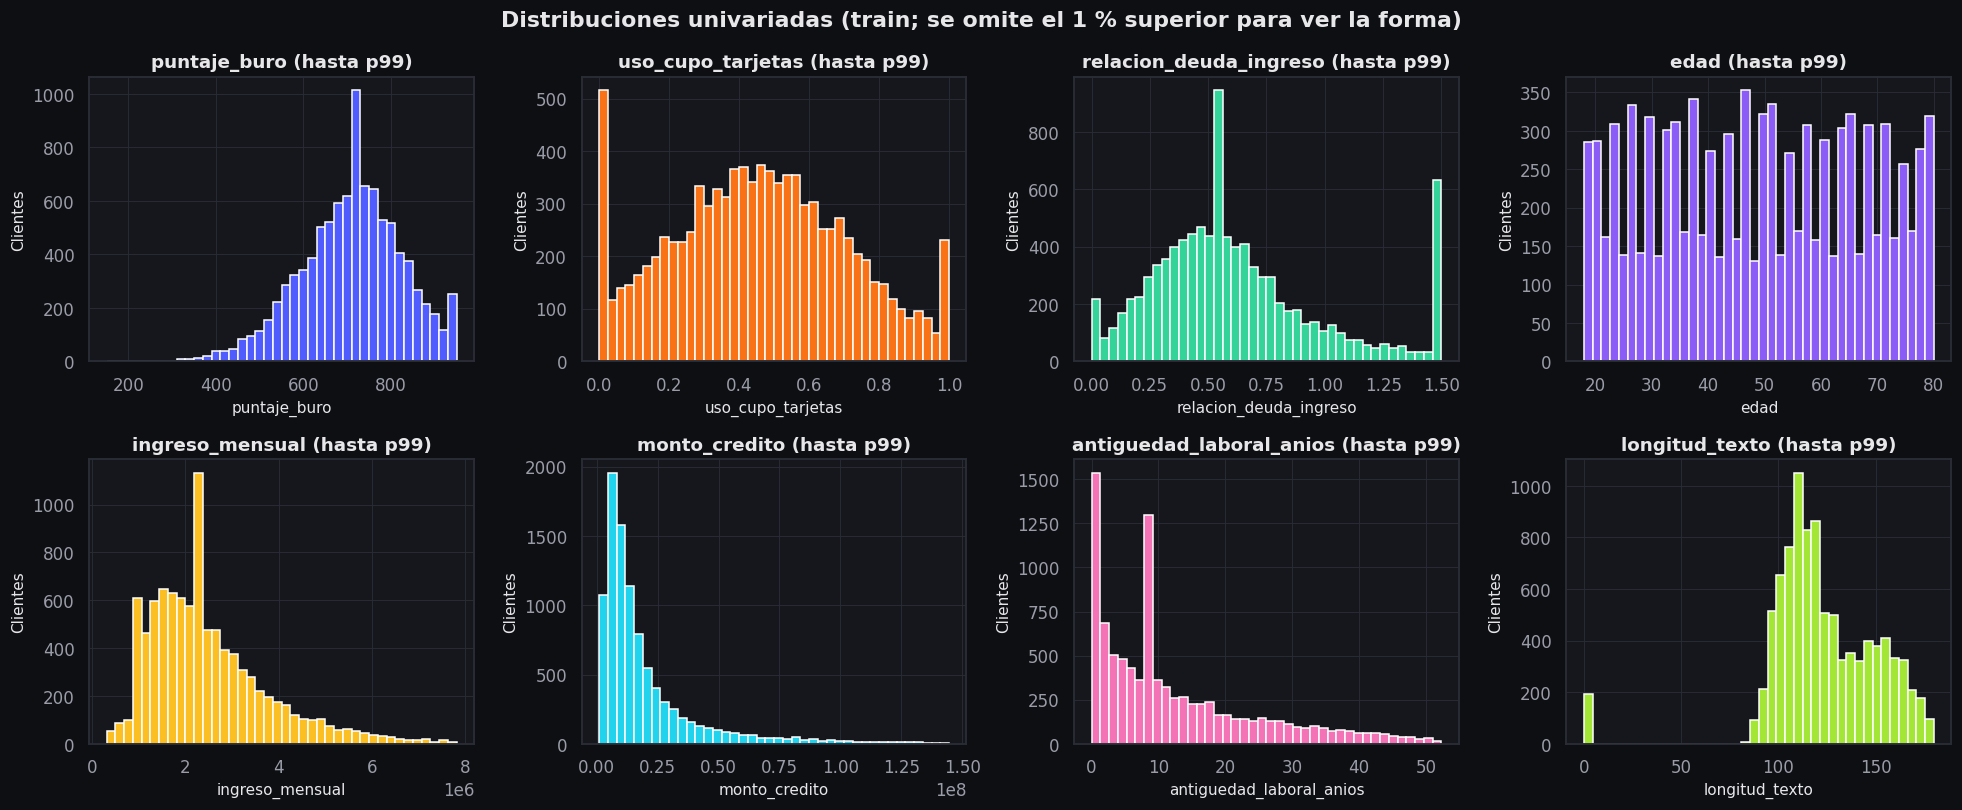

In [6]:
VARS_UNI = ["puntaje_buro", "uso_cupo_tarjetas", "relacion_deuda_ingreso", "edad",
            "ingreso_mensual", "monto_credito", "antiguedad_laboral_anios", "longitud_texto"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, col, color in zip(axes.ravel(), VARS_UNI, SERIE):
    datos = df[col][df[col] <= df[col].quantile(0.99)]
    conteos, bordes = np.histogram(datos, bins=40)
    ax.hist(datos, bins=bordes, color=color)
    ax.set(title=f"{col} (hasta p99)", xlabel=col, ylabel="Clientes")
    figura_front("histograma", f"Distribución de {col} (hasta p99)",
                 {"bordes": r4(bordes), "series": [{"nombre": col, "conteos": conteos.tolist()}]},
                 ejes={"x": col, "y": "Clientes"}, clave=f"univariado_{col}",
                 opciones={"formato_x": "cop" if col in ("ingreso_mensual", "monto_credito") else "num"})
plt.suptitle("Distribuciones univariadas (train; se omite el 1 % superior para ver la forma)", fontweight="bold")
plt.show()

**Interpretación.** `edad` es casi uniforme entre 18 y 80 años (asimetría 0,01; el patrón alterno de las barras se
debe a que es entera). `puntaje_buro` tiene forma de campana con cola izquierda (asimetría −0,37) y un tope en
950, el máximo de la escala; `uso_cupo_tarjetas` acumula clientes en 0 y en 1. Los picos aislados en
`puntaje_buro` (710-730), `relacion_deuda_ingreso` (≈ 0,55), `ingreso_mensual` (≈ 2,2 millones) y
`antiguedad_laboral_anios` (≈ 9 años) coinciden con las medianas imputadas en el paso 3: son la huella de la
imputación. `longitud_texto` tiene 192 ceros ("Sin texto") y la mayoría entre ≈ 80 y 180 caracteres. Las variables
monetarias son muy asimétricas aun sin el 1 % superior; en la tabla, la asimetría del ingreso es 10,8 (curtosis
244) y su máximo es 8,3 veces el p99; monto y cuota se comportan igual (asimetría ≈ 9,5-9,7).

In [7]:
resumen_cat = pd.DataFrame([{"variable": c, "categorias": df[c].nunique(),
                             "mas_frecuente": df[c].value_counts().index[0],
                             "pct_mas_frecuente": df[c].value_counts(normalize=True).iloc[0] * 100,
                             "menos_frecuente": df[c].value_counts().index[-1],
                             "pct_menos_frecuente": df[c].value_counts(normalize=True).iloc[-1] * 100}
                            for c in CAT]).set_index("variable")
resumen_cat.round(1)

,categorias,mas_frecuente,pct_mas_frecuente,menos_frecuente,pct_menos_frecuente
variable,,,,,
sexo,2,M,51.9000,F,48.1000
estado_civil,5,Soltero,37.4000,Viudo,5.0000
situacion_laboral,5,Empleado,53.2000,Desconocido,4.0000
tipo_vivienda,4,Arriendo,41.2000,Desconocido,3.3000
proposito,6,Libre_inversion,28.3000,Educacion,10.0000
nivel_educativo,5,Secundaria,29.5000,Posgrado,8.1000
rango_edad,5,>60,31.3000,18-25,12.3000
tiene_moras_previas,2,0,66.1000,1,33.9000


### 1.2 Bivariado: cada variable frente a `default`

Numéricas: medianas por clase y prueba de **Mann-Whitney** (no paramétrica, adecuada para distribuciones
asimétricas). Categóricas: tasa de impago por categoría frente a la tasa global.

In [8]:
biv = pd.DataFrame({
    "mediana_pago": df.loc[df[T] == 0, NUM].median(),
    "mediana_impago": df.loc[df[T] == 1, NUM].median(),
    "p_valor_mann_whitney": [stats.mannwhitneyu(df.loc[df[T] == 0, c], df.loc[df[T] == 1, c]).pvalue for c in NUM],
})
biv["significativa_5%"] = biv["p_valor_mann_whitney"] < 0.05
biv.sort_values("p_valor_mann_whitney")

,mediana_pago,mediana_impago,p_valor_mann_whitney,significativa_5%
moras_ultimos_12m,0.0000,1.0000,0.0000,True
puntaje_buro,752.0000,633.0000,0.0000,True
uso_cupo_tarjetas,0.3590,0.6220,0.0000,True
relacion_deuda_ingreso,0.4870,0.6840,0.0000,True
antiguedad_laboral_anios,9.0000,8.6000,0.0000,True
ingreso_mensual,"2,234,000.0000","2,201,500.0000",0.0000,True
personas_a_cargo,1.0000,1.0000,0.0000,True
edad,50.0000,46.0000,0.0000,True
ratio_monto_ingreso,5.0073,5.4703,0.0000,True
longitud_texto,119.0000,121.0000,0.0000,True


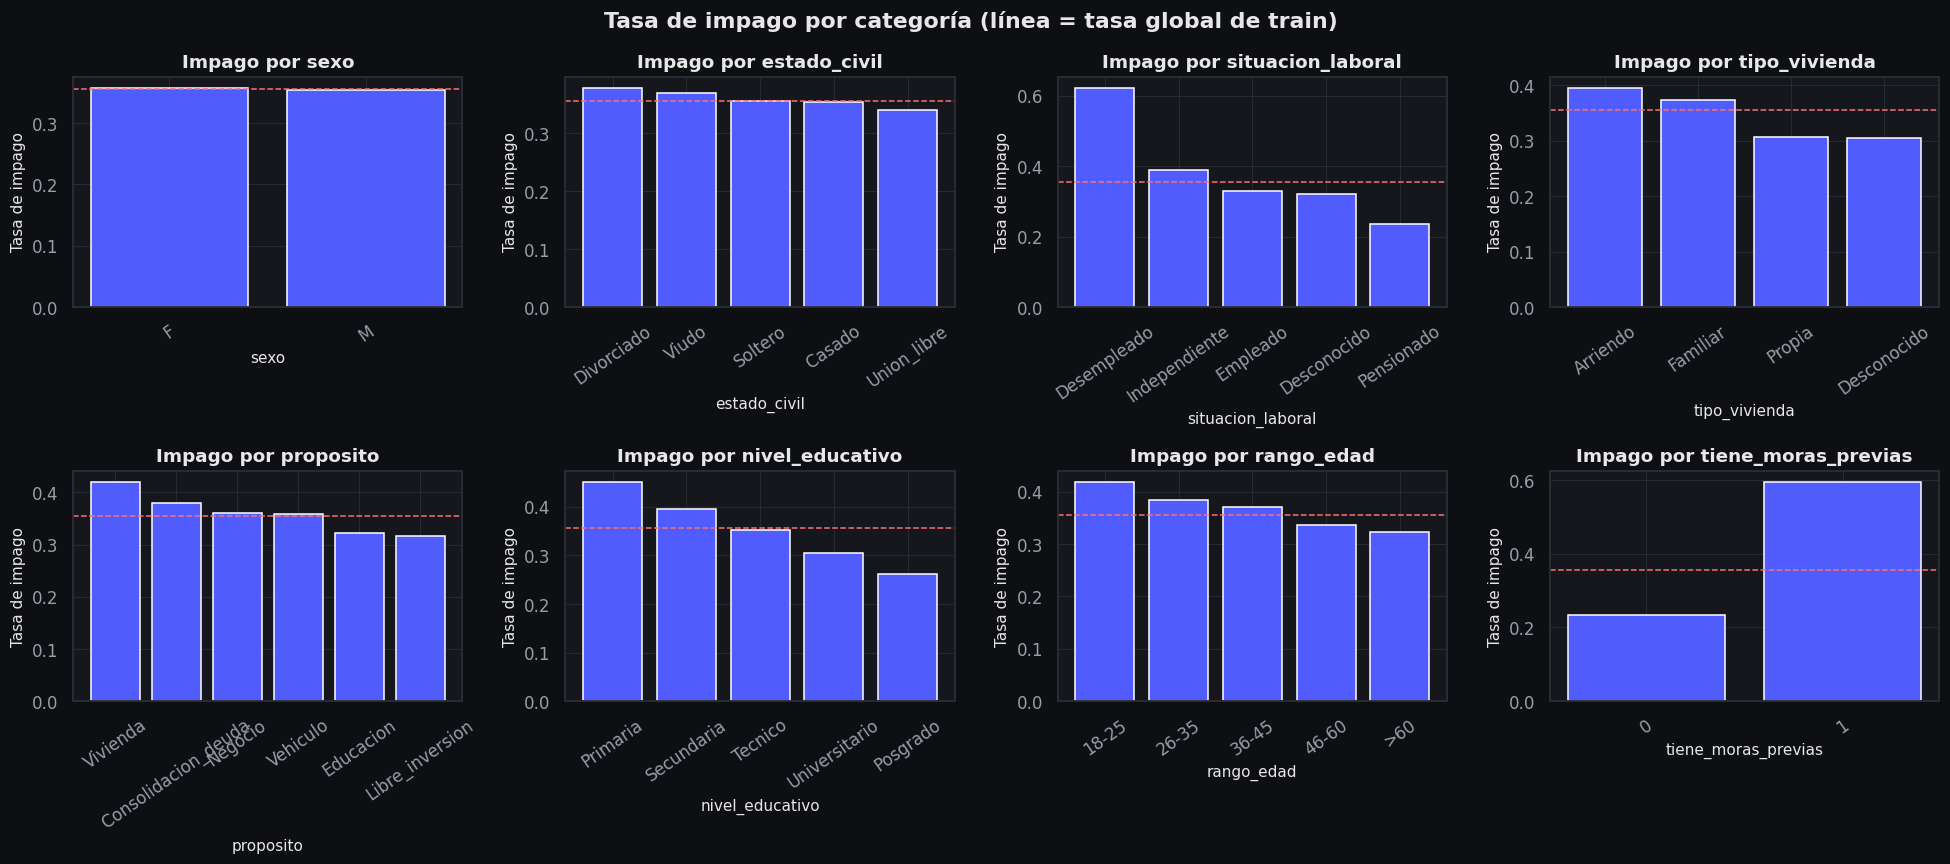

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), CAT):
    t = df.groupby(col)[T].mean()
    t = t.reindex(ORDEN[col]) if col in ORDEN else t.sort_values(ascending=False)
    etiquetas = [str(i) for i in t.index]
    ax.bar(etiquetas, t.values, color=PALETA["acento"])
    ax.axhline(TASA, ls="--", color=PALETA["alto"], lw=1)
    ax.set(title=f"Impago por {col}", xlabel=col, ylabel="Tasa de impago")
    ax.tick_params(axis="x", rotation=35)
    figura_front("barras", f"Tasa de impago por {col}",
                 {"categorias": etiquetas, "series": [{"nombre": "Tasa de impago", "valores": r4(t.values)}],
                  "referencias": [{"eje": "y", "valor": round(float(TASA), 4), "etiqueta": "tasa global"}]},
                 ejes={"x": col, "y": "Tasa de impago"}, clave=f"impago_por_{col}", opciones={"formato_y": "pct"})
plt.suptitle("Tasa de impago por categoría (línea = tasa global de train)", fontweight="bold")
plt.show()

**Interpretación.** 12 de las 16 numéricas difieren significativamente entre pagadores e impagos
(Mann-Whitney, p < 0,05). Las diferencias grandes están en `puntaje_buro` (mediana 752 frente a 633),
`uso_cupo_tarjetas` (0,36 frente a 0,62), `relacion_deuda_ingreso` (0,49 frente a 0,68) y `moras_ultimos_12m`
(0 frente a 1). Otras son significativas pero pequeñas (ingreso 2,234 frente a 2,202 millones): con 9.600 filas,
significativo no equivale a relevante. Las condiciones del crédito, `monto_credito`, `tasa_interes_anual`,
`cuota_estimada` y `plazo_meses`, **no** difieren (p entre 0,54 y 0,74). En las categóricas, el impago va de
23,3 % sin moras a 59,6 % con moras; de 23,7 % en pensionados a 62,3 % en desempleados; baja con la educación
(45,2 % en primaria, 26,3 % en posgrado) y con la edad (41,9 % en 18-25, 32,3 % en >60); es mayor en arriendo
(39,5 %) que en vivienda propia (30,6 %) y en crédito de vivienda (42,1 %) que en libre inversión (31,7 %).
`sexo` (35,8 % F, 35,4 % M) y `estado_civil` (34,1-37,9 %) quedan pegados a la tasa global.

### 1.3 Multivariado: los factores de riesgo se combinan

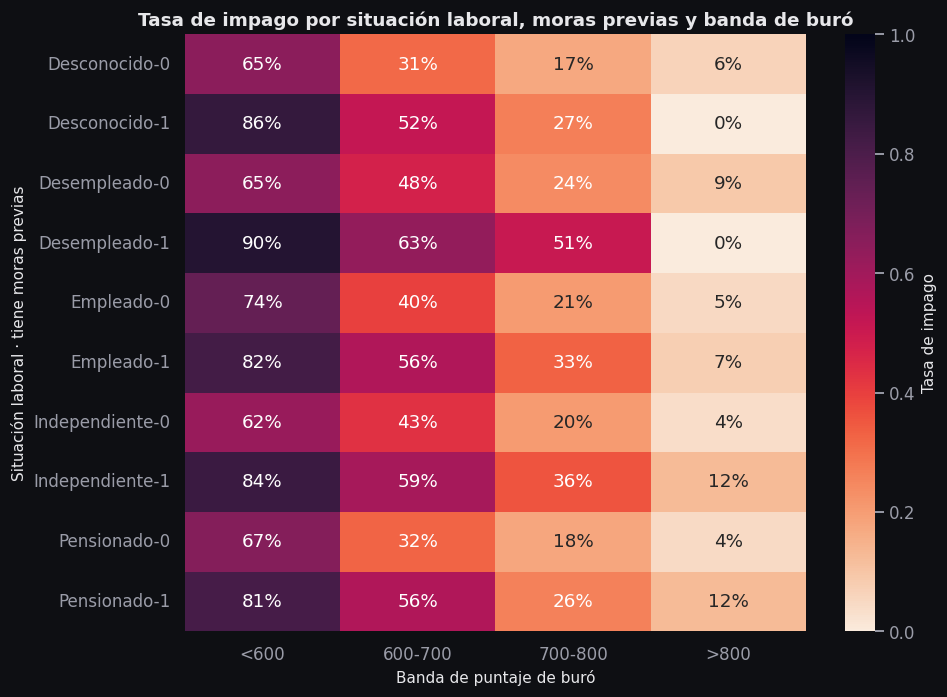

In [10]:
BANDAS_BURO = ([0, 600, 700, 800, 1000], ["<600", "600-700", "700-800", ">800"])
seg = (df.assign(banda_buro=pd.cut(df["puntaje_buro"], *BANDAS_BURO[:1], labels=BANDAS_BURO[1]))
         .pivot_table(index=["situacion_laboral", "tiene_moras_previas"], columns="banda_buro", values=T,
                      aggfunc="mean", observed=True))
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(seg, annot=True, fmt=".0%", cmap="rocket_r", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Tasa de impago"})
ax.set(title="Tasa de impago por situación laboral, moras previas y banda de buró",
       xlabel="Banda de puntaje de buró", ylabel="Situación laboral · tiene moras previas")
plt.show()
figura_front("heatmap", "Tasa de impago por situación laboral, moras previas y banda de buró",
             {"x": [str(c) for c in seg.columns], "y": [f"{a} · {'con' if b else 'sin'} moras" for a, b in seg.index],
              "valores": [r4(f) for f in seg.to_numpy()]},
             ejes={"x": "Banda de puntaje de buró", "y": "Situación laboral · moras previas"},
             clave="segmentos_laboral_moras_buro", opciones={"formato_valor": "pct"})

**Interpretación.** Los factores **se acumulan**. Dentro de cada situación laboral el impago cae con fuerza al
subir la banda de buró, y en casi todas las bandas tener moras previas lo aumenta. Los extremos: un desempleado
con moras y buró < 600 tiene 90,3 % de impago; un empleado sin moras y buró > 800, 4,8 %. Incluso los
pensionados, el grupo de menor riesgo, llegan a 81,4 % con moras y buró < 600. Las únicas excepciones están en la
banda > 800 de desempleados y "Desconocido" con moras (0 %), que conviene leer con cautela. El riesgo es
multivariado, lo que justifica modelos que combinen variables.

### 1.4 Segmentos con SQL (DuckDB en proceso)

DuckDB consulta el DataFrame en memoria con SQL analítico (sin servidor ni copia a una base). Es la misma
estrategia que usa el exportador del front para calcular agregados.

In [11]:
con = duckdb.connect()  # base en memoria
con.register("train", df)
top_segmentos = con.sql("""
    SELECT situacion_laboral, rango_edad,
           COUNT(*)                         AS clientes,
           ROUND(AVG("default"), 4)         AS tasa_impago,
           MEDIAN(puntaje_buro)             AS buro_mediano
    FROM train
    GROUP BY ALL
    HAVING COUNT(*) >= 30
    ORDER BY tasa_impago DESC
    LIMIT 8
""").df()
top_segmentos

,situacion_laboral,rango_edad,clientes,tasa_impago,buro_mediano
0,Desempleado,18-25,98,0.7143,615.5000
1,Desempleado,26-35,105,0.6476,607.0000
2,Desempleado,36-45,105,0.6381,611.0000
3,Desempleado,46-60,162,0.6111,605.0000
4,Desempleado,>60,169,0.5562,619.0000
5,Independiente,18-25,331,0.4864,687.0000
6,Independiente,26-35,391,0.4373,683.0000
7,Desconocido,18-25,54,0.3889,690.0000


In [12]:
por_banda = con.sql("""
    SELECT CASE WHEN puntaje_buro < 600 THEN '1. <600'
                WHEN puntaje_buro < 700 THEN '2. 600-700'
                WHEN puntaje_buro < 800 THEN '3. 700-800'
                ELSE '4. >800' END                           AS banda_buro,
           COUNT(*)                                          AS clientes,
           ROUND(COUNT(*) / SUM(COUNT(*)) OVER (), 4)        AS pct_cartera,
           ROUND(AVG("default"), 4)                          AS tasa_impago,
           ROUND(SUM("default") / SUM(SUM("default")) OVER (), 4) AS pct_de_los_impagos
    FROM train GROUP BY 1 ORDER BY 1
""").df()
sql_prop = con.sql('SELECT proposito, AVG("default") AS tasa FROM train GROUP BY 1').df().set_index("proposito")["tasa"]
assert np.allclose(sql_prop.sort_index(), df.groupby("proposito")[T].mean().sort_index())
print("✔ La tasa por propósito calculada con SQL coincide con la de pandas")
por_banda

✔ La tasa por propósito calculada con SQL coincide con la de pandas


,banda_buro,clientes,pct_cartera,tasa_impago,pct_de_los_impagos
0,1. <600,1629,0.1697,0.8097,0.3864
1,2. 600-700,2509,0.2614,0.4735,0.3480
2,3. 700-800,3402,0.3544,0.2354,0.2346
3,4. >800,2060,0.2146,0.0515,0.0310


**Lectura.** Los cinco segmentos de mayor impago son desempleados de todas las edades (de
71,4 % en 18-25 a 55,6 % en >60), seguidos de independientes de 18-25 (48,6 %). Por banda de buró, los clientes
con menos de 600 puntos son el 17,0 % de la cartera pero concentran el 38,6 % de los impagos (tasa de 81,0 %),
mientras que los de más de 800 son el 21,5 % y aportan solo el 3,1 %. La consulta SQL y pandas dan el mismo
resultado.

## 2. IA2.1 / IA2.2 · Manipulación de datos con pandas
### 2.1 `groupby` con varias agregaciones y `merge`

In [13]:
tasa_proposito = (df.groupby("proposito")
                    .agg(clientes=(T, "size"), tasa_impago_proposito=(T, "mean"),
                         monto_mediano=("monto_credito", "median"), plazo_medio=("plazo_meses", "mean"))
                    .reset_index())
tasa_laboral = (df.groupby("situacion_laboral", as_index=False)[T].mean()
                  .rename(columns={T: "tasa_impago_laboral"}))
# merge: cada cliente recibe la tasa de su segmento (codificación por objetivo exploratoria, solo en train)
df_seg = (df.merge(tasa_proposito[["proposito", "tasa_impago_proposito"]], on="proposito", how="left")
            .merge(tasa_laboral, on="situacion_laboral", how="left"))
display(tasa_proposito.round(3))
df_seg[[ID, "proposito", "tasa_impago_proposito", "situacion_laboral", "tasa_impago_laboral", T]].head()

,proposito,clientes,tasa_impago_proposito,monto_mediano,plazo_medio
0,Consolidacion_deuda,1550,0.3800,"8,857,000.0000",32.0710
1,Educacion,958,0.3230,"10,630,500.0000",31.3530
2,Libre_inversion,2720,0.3170,"7,158,000.0000",32.4110
3,Negocio,1364,0.3610,"14,115,500.0000",33.5670
4,Vehiculo,1651,0.3590,"18,598,000.0000",33.2560
5,Vivienda,1357,0.4210,"55,057,000.0000",31.9680


,id_cliente,proposito,tasa_impago_proposito,situacion_laboral,tasa_impago_laboral,default
0,CLI_000001,Negocio,0.3607,Empleado,0.3288,0
1,CLI_000002,Negocio,0.3607,Empleado,0.3288,1
2,CLI_000004,Libre_inversion,0.3165,Independiente,0.3888,1
3,CLI_000005,Libre_inversion,0.3165,Independiente,0.3888,1
4,CLI_000007,Libre_inversion,0.3165,Desempleado,0.6228,1


### 2.2 `melt` (ancho → largo) y `pivot` (largo → ancho)

In [14]:
largo = df[[ID, T, "puntaje_buro", "uso_cupo_tarjetas", "relacion_deuda_ingreso"]].melt(
    id_vars=[ID, T], var_name="variable", value_name="valor")
print(f"melt: {df.shape[0]:,} filas anchas → {largo.shape[0]:,} filas largas")
display(largo.head(4))
(largo.groupby(["variable", T])["valor"].mean().reset_index()
      .pivot(index="variable", columns=T, values="valor").rename(columns=ETIQUETA).round(3))

melt: 9,600 filas anchas → 28,800 filas largas


,id_cliente,default,variable,valor
0,CLI_000001,0,puntaje_buro,700.0000
1,CLI_000002,1,puntaje_buro,913.0000
2,CLI_000004,1,puntaje_buro,436.0000
3,CLI_000005,1,puntaje_buro,715.0000


default,Pagó,Impago
variable,,
puntaje_buro,754.8570,625.2430
relacion_deuda_ingreso,0.5390,0.7670
uso_cupo_tarjetas,0.3610,0.6240


### 2.3 `map`, `apply`, `cut` y `qcut`

In [15]:
ejemplo = df[["edad", "ingreso_mensual", "puntaje_buro", "nivel_educativo", "moras_ultimos_12m", T]].copy()
ejemplo["educacion_codigo"] = ejemplo["nivel_educativo"].map({n: i for i, n in enumerate(config.ORDINALES["nivel_educativo"])})
ejemplo["alerta"] = ejemplo.apply(lambda r: "Alta" if r["puntaje_buro"] < 600 and r["moras_ultimos_12m"] > 0 else "Normal",
                                  axis=1)
ejemplo["banda_buro"] = pd.cut(ejemplo["puntaje_buro"], bins=BANDAS_BURO[0], labels=["Malo", "Regular", "Bueno", "Excelente"])
ejemplo["quintil_ingreso"] = pd.qcut(ejemplo["ingreso_mensual"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
display(ejemplo.head())
display(pd.crosstab(ejemplo["banda_buro"], ejemplo[T], normalize="index").rename(columns=ETIQUETA).round(3))
ejemplo.groupby("alerta")[T].agg(clientes="size", tasa_impago="mean").round(3)

,edad,ingreso_mensual,puntaje_buro,nivel_educativo,moras_ultimos_12m,default,educacion_codigo,alerta,banda_buro,quintil_ingreso
0,23,"1,197,000.0000",700,Secundaria,0,0,1,Normal,Regular,Q1
1,66,"7,763,000.0000",913,Tecnico,0,1,2,Normal,Excelente,Q5
2,45,"2,024,000.0000",436,Primaria,2,1,0,Alta,Malo,Q3
3,45,"1,000,000.0000",715,Secundaria,3,1,1,Normal,Bueno,Q1
4,23,"678,000.0000",515,Secundaria,1,1,1,Alta,Malo,Q1


default,Pagó,Impago
banda_buro,,
Malo,0.1920,0.8080
Regular,0.5280,0.4720
Bueno,0.7650,0.2350
Excelente,0.9510,0.0490


,clientes,tasa_impago
alerta,,
Alta,1260,0.8480
Normal,8340,0.2810


### 2.4 Encadenamiento con `assign` y `pipe`

In [16]:
def filtrar_minimo(d: pd.DataFrame, col: str, minimo: float) -> pd.DataFrame:
    return d[d[col] >= minimo]


def resumen_por(d: pd.DataFrame, col: str) -> pd.DataFrame:
    return d.groupby(col, observed=True).agg(clientes=(T, "size"), tasa_impago=(T, "mean"),
                                             cuota_ingreso_mediana=("ratio_cuota_ingreso", "median"))


quintiles_ingreso = (df.assign(log_ingreso=lambda d: np.log1p(d["ingreso_mensual"]),
                               quintil_ingreso=lambda d: pd.qcut(d["log_ingreso"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]))
                       .pipe(filtrar_minimo, "plazo_meses", 6)
                       .pipe(resumen_por, "quintil_ingreso"))
quintiles_ingreso.round(3)

,clientes,tasa_impago,cuota_ingreso_mediana
quintil_ingreso,,,
Q1,1923,0.4450,0.2800
Q2,1918,0.3420,0.2740
Q3,1921,0.3470,0.2740
Q4,1918,0.3240,0.2780
Q5,1920,0.3200,0.2810


**Lectura.** El impago baja del 44,5 % en el quintil de ingreso más bajo a 32,0 % en el más alto,
mientras que la carga cuota/ingreso mediana es casi igual en todos los quintiles (0,27-0,28): el mayor riesgo
de los ingresos bajos no se explica por una cuota relativamente más pesada. En 2.3, la regla `apply` de
alerta (buró < 600 con moras) marca a 1.260 clientes con 84,8 % de impago, frente a 28,1 % del resto, y la banda
de buró creada con `cut` va de 80,8 % de impago ("Malo") a 4,9 % ("Excelente").

### 2.5 dplyr en Python: cada verbo con su equivalente en pandas

El proyecto es 100 % Python, así que la gramática de **dplyr** se ejecuta con pandas encadenado. El código R
se muestra solo como referencia (no se ejecuta).

| Verbo dplyr (R) | Equivalente pandas | Qué hace |
|---|---|---|
| `filter(moras_ultimos_12m > 0, puntaje_buro < 600)` | `.query("moras_ultimos_12m > 0 and puntaje_buro < 600")` | Filtra filas |
| `select(id_cliente, edad, default)` | `[["id_cliente", "edad", "default"]]` | Selecciona columnas |
| `mutate(cuota_pct = ratio_cuota_ingreso * 100)` | `.assign(cuota_pct=lambda d: d.ratio_cuota_ingreso * 100)` | Crea o modifica columnas |
| `group_by(x) %>% summarise(n = n(), tasa = mean(default))` | `.groupby("x").agg(n=("default", "size"), tasa=("default", "mean"))` | Agrega por grupo |
| `arrange(desc(tasa))` | `.sort_values("tasa", ascending=False)` | Ordena |
| `%>%` (pipe) | encadenar métodos `( ... )` y `.pipe(f)` | Compone pasos |

```r
library(dplyr)
creditos %>%
  filter(plazo_meses >= 12) %>%
  mutate(banda_buro = cut(puntaje_buro, c(0, 600, 700, 800, 1000))) %>%
  group_by(situacion_laboral, banda_buro) %>%
  summarise(clientes = n(), tasa_impago = mean(default), .groups = "drop") %>%
  filter(clientes >= 30) %>%
  arrange(desc(tasa_impago)) %>%
  select(situacion_laboral, banda_buro, clientes, tasa_impago)
```

In [17]:
# dplyr: creditos %>% filter(moras_ultimos_12m > 0, puntaje_buro < 600)
riesgosos = df.query("moras_ultimos_12m > 0 and puntaje_buro < 600")
print(f"filter → {len(riesgosos):,} clientes con moras y buró < 600 (tasa de impago {riesgosos[T].mean():.1%})")

filter → 1,260 clientes con moras y buró < 600 (tasa de impago 84.8%)


In [18]:
# dplyr: creditos %>% select(id_cliente, edad, ingreso_mensual, default)
df[[ID, "edad", "ingreso_mensual", T]].head(3)

,id_cliente,edad,ingreso_mensual,default
0,CLI_000001,23,"1,197,000.0000",0
1,CLI_000002,66,"7,763,000.0000",1
2,CLI_000004,45,"2,024,000.0000",1


In [19]:
# dplyr: creditos %>% mutate(cuota_pct_ingreso = ratio_cuota_ingreso * 100, joven = edad < 26)
df.assign(cuota_pct_ingreso=lambda d: d["ratio_cuota_ingreso"] * 100, joven=lambda d: d["edad"] < 26)[
    [ID, "ratio_cuota_ingreso", "cuota_pct_ingreso", "edad", "joven"]].head(3)

,id_cliente,ratio_cuota_ingreso,cuota_pct_ingreso,edad,joven
0,CLI_000001,1.8134,181.3366,23,True
1,CLI_000002,0.4934,49.3383,66,False
2,CLI_000004,0.3619,36.1901,45,False


In [20]:
# dplyr: creditos %>% group_by(situacion_laboral) %>% summarise(clientes = n(), tasa_impago = mean(default),
#                                                                ingreso_mediano = median(ingreso_mensual))
por_laboral = df.groupby("situacion_laboral").agg(clientes=(T, "size"), tasa_impago=(T, "mean"),
                                                  ingreso_mediano=("ingreso_mensual", "median"))
por_laboral

,clientes,tasa_impago,ingreso_mediano
situacion_laboral,,,
Desconocido,384,0.3203,"2,234,000.0000"
Desempleado,639,0.6228,"1,062,000.0000"
Empleado,5107,0.3288,"2,246,000.0000"
Independiente,2580,0.3888,"2,234,000.0000"
Pensionado,890,0.2371,"2,234,000.0000"


In [21]:
# dplyr: ... %>% arrange(desc(tasa_impago))
por_laboral.sort_values("tasa_impago", ascending=False)

,clientes,tasa_impago,ingreso_mediano
situacion_laboral,,,
Desempleado,639,0.6228,"1,062,000.0000"
Independiente,2580,0.3888,"2,234,000.0000"
Empleado,5107,0.3288,"2,246,000.0000"
Desconocido,384,0.3203,"2,234,000.0000"
Pensionado,890,0.2371,"2,234,000.0000"


In [22]:
# dplyr: la cadena completa con %>% (ver el bloque R de arriba), traducida a un solo encadenamiento de pandas
cadena = (df.query("plazo_meses >= 12")                                                          # filter
            .assign(banda_buro=lambda d: pd.cut(d["puntaje_buro"], BANDAS_BURO[0], labels=BANDAS_BURO[1]))  # mutate
            .groupby(["situacion_laboral", "banda_buro"], observed=True)                         # group_by
            .agg(clientes=(T, "size"), tasa_impago=(T, "mean"))                                  # summarise
            .reset_index()
            .query("clientes >= 30")                                                             # filter
            .sort_values("tasa_impago", ascending=False)                                         # arrange
            .pipe(lambda d: d[["situacion_laboral", "banda_buro", "clientes", "tasa_impago"]]))  # select vía pipe
cadena.head(8)

,situacion_laboral,banda_buro,clientes,tasa_impago
4,Desempleado,<600,285,0.8667
16,Pensionado,<600,54,0.8148
0,Desconocido,<600,66,0.8030
8,Empleado,<600,672,0.8006
12,Independiente,<600,489,0.7853
5,Desempleado,600-700,161,0.5404
13,Independiente,600-700,672,0.4955
9,Empleado,600-700,1259,0.4678


**Lectura.** Cada verbo de dplyr tiene un equivalente directo en pandas y la cadena se lee de
arriba abajo como el *pipe* de R. `filter` aísla a los 1.260 clientes con moras y buró < 600 (84,8 % de impago,
los mismos de la alerta de 2.3); `group_by` + `summarise` + `arrange` muestran que los desempleados tienen la mayor
tasa (62,3 %) y un ingreso mediano de 1.062.000, menos de la mitad que el resto (≈ 2,23 millones). En la cadena
completa, los cinco segmentos de mayor impago tienen buró < 600, sea cual sea la situación laboral (de 78,5 % a
86,7 %): la banda de buró pesa más que la situación laboral.

## 3. IA2.3 · Visualización con las tres librerías
### 3.1 Matplotlib: figura con subplots

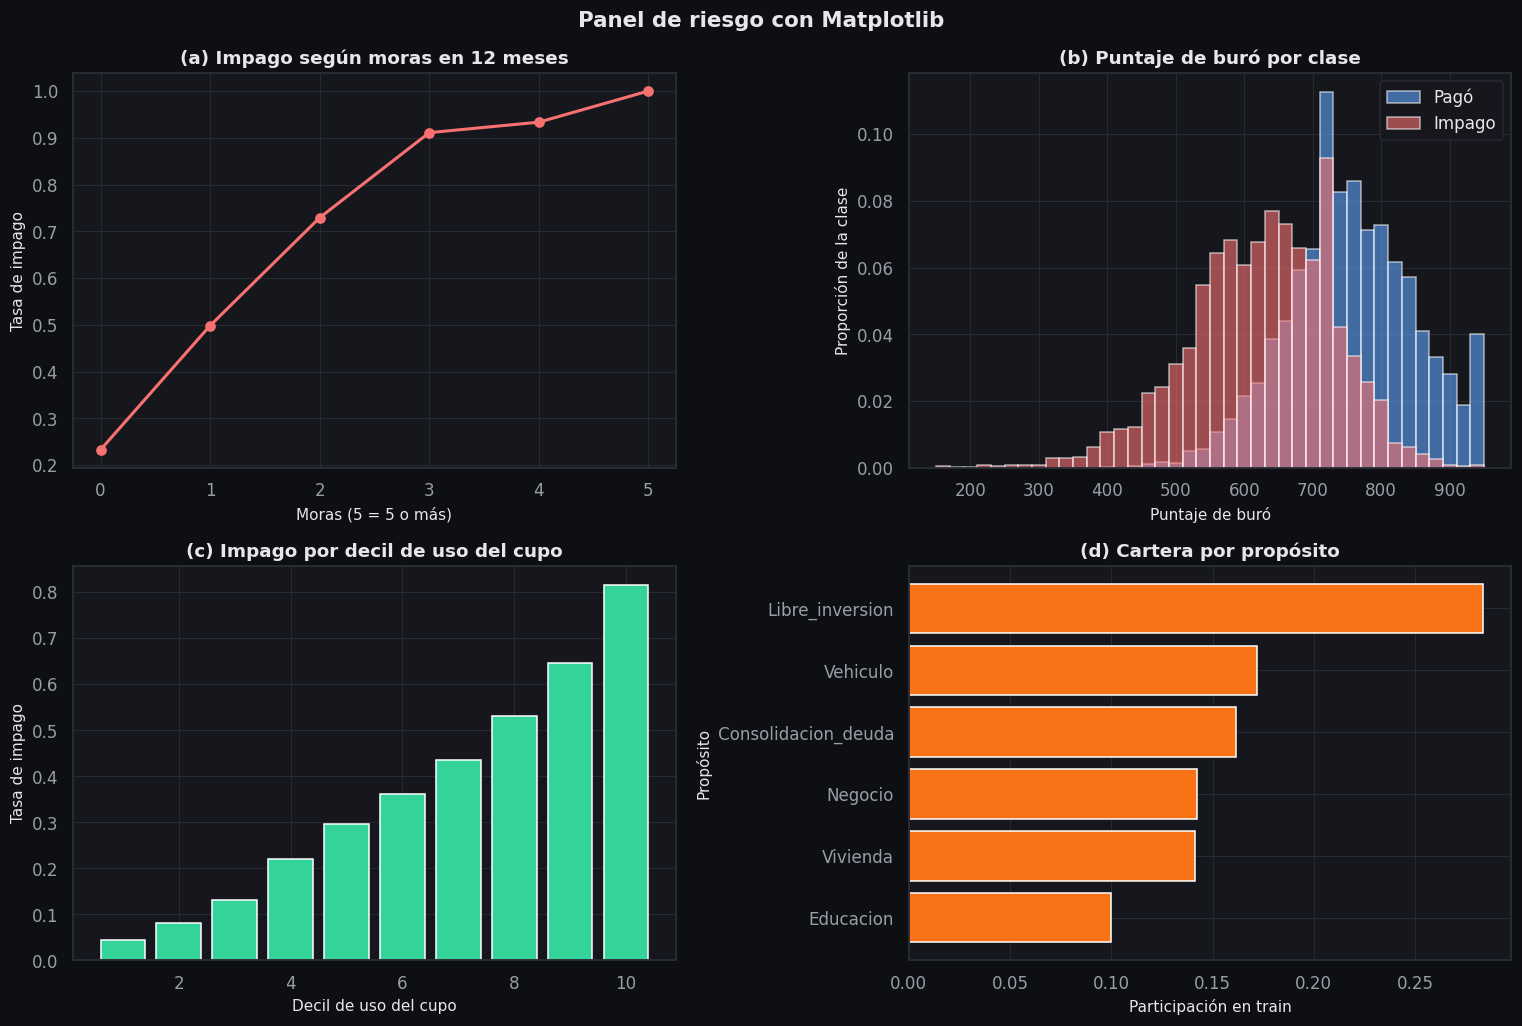

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
# (a) impago según el número de moras
moras = df.groupby(df["moras_ultimos_12m"].clip(upper=5))[T].mean()
axes[0, 0].plot(moras.index, moras.values, marker="o", color=PALETA["alto"], lw=2)
axes[0, 0].set(title="(a) Impago según moras en 12 meses", xlabel="Moras (5 = 5 o más)", ylabel="Tasa de impago")
figura_front("lineas", "Impago según moras en los últimos 12 meses",
             {"series": [{"nombre": "Tasa de impago", "x": moras.index.tolist(), "y": r4(moras.values)}]},
             ejes={"x": "Moras (5 = 5 o más)", "y": "Tasa de impago"}, clave="mpl_impago_por_moras",
             opciones={"formato_y": "pct"})
# (b) distribución del buró por clase (proporción de cada clase por intervalo)
bordes = np.histogram_bin_edges(df["puntaje_buro"], bins=40)
series_b = []
for k in (0, 1):
    v = df.loc[df[T] == k, "puntaje_buro"]
    prop = np.histogram(v, bins=bordes)[0] / len(v)
    axes[0, 1].hist(v, bins=bordes, weights=np.full(len(v), 1 / len(v)), alpha=0.6, color=COLORES_CLASE[k],
                    label=ETIQUETA[k])
    series_b.append({"nombre": ETIQUETA[k], "conteos": r4(prop)})
axes[0, 1].set(title="(b) Puntaje de buró por clase", xlabel="Puntaje de buró", ylabel="Proporción de la clase")
axes[0, 1].legend()
figura_front("histograma", "Puntaje de buró por clase", {"bordes": r4(bordes), "series": series_b},
             ejes={"x": "Puntaje de buró", "y": "Proporción de la clase"}, clave="mpl_buro_por_clase",
             opciones={"formato_y": "pct"})
# (c) impago por decil de uso del cupo
dec = df.groupby(pd.qcut(df["uso_cupo_tarjetas"], 10, labels=False, duplicates="drop"))[T].mean()
axes[1, 0].bar(dec.index + 1, dec.values, color=PALETA["bajo"])
axes[1, 0].set(title="(c) Impago por decil de uso del cupo", xlabel="Decil de uso del cupo", ylabel="Tasa de impago")
figura_front("barras", "Impago por decil de uso del cupo de tarjetas",
             {"categorias": [f"D{i + 1}" for i in dec.index], "series": [{"nombre": "Tasa de impago", "valores": r4(dec.values)}]},
             ejes={"x": "Decil de uso del cupo", "y": "Tasa de impago"}, clave="mpl_impago_por_decil_cupo",
             opciones={"formato_y": "pct"})
# (d) composición de la cartera por propósito
cartera = df["proposito"].value_counts(normalize=True).sort_values()
axes[1, 1].barh(cartera.index, cartera.values, color=PALETA["programacion"])
axes[1, 1].set(title="(d) Cartera por propósito", xlabel="Participación en train", ylabel="Propósito")
figura_front("barras_h", "Cartera por propósito del crédito",
             {"categorias": list(cartera.index), "series": [{"nombre": "Participación", "valores": r4(cartera.values)}]},
             ejes={"x": "Participación en train", "y": "Propósito"}, clave="mpl_cartera_por_proposito",
             opciones={"formato_x": "pct"})
plt.suptitle("Panel de riesgo con Matplotlib", fontsize=14, fontweight="bold")
plt.show()

**Interpretación.** (a) El impago crece con cada mora: 23,3 % sin moras, 49,8 % con una, 72,9 % con
dos, 91,1 % con tres y 100 % en el grupo de 5 o más. (b) La distribución del buró de los impagos está desplazada
hacia la izquierda respecto a la de los pagadores, aunque las dos se solapan. (c) El impago sube de forma
monótona con el uso del cupo, de 4,3 % en el primer decil a 81,7 % en el décimo. (d) Libre inversión es el
propósito más frecuente (28,3 % de la cartera) y educación el menos frecuente (10,0 %).

### 3.2 Seaborn: `heatmap` de correlaciones, `pairplot` y `violinplot`

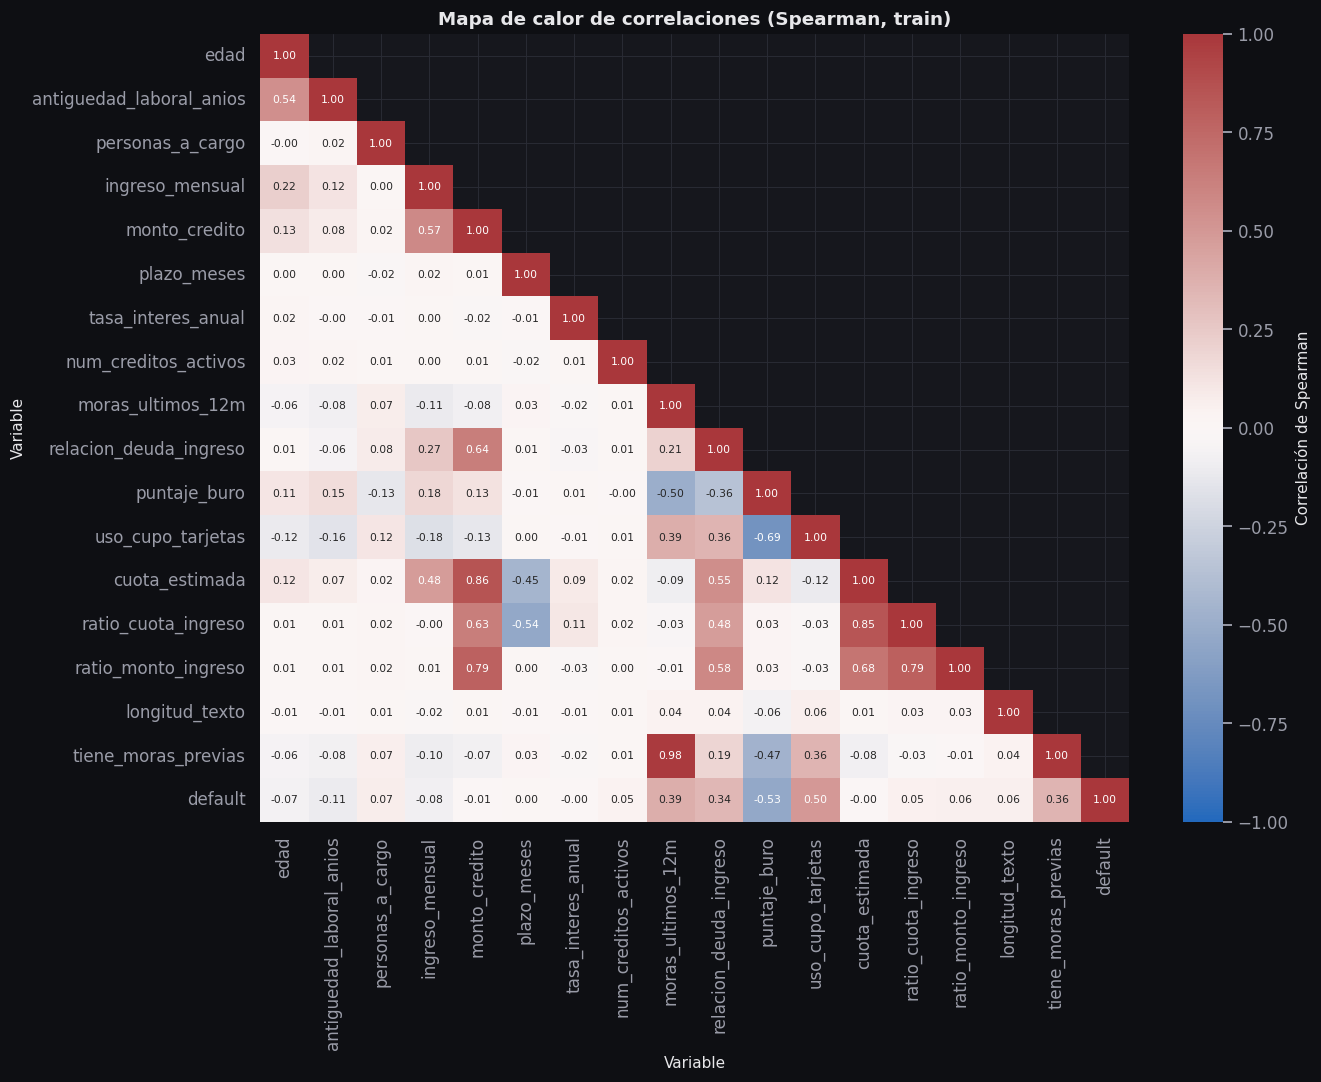

In [24]:
corr_s = df[NUM + ["tiene_moras_previas", T]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12.5, 10))
sns.heatmap(corr_s, mask=np.triu(np.ones_like(corr_s, dtype=bool), k=1), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "Correlación de Spearman"})
ax.set(title="Mapa de calor de correlaciones (Spearman, train)", xlabel="Variable", ylabel="Variable")
plt.show()
figura_front("heatmap", "Correlaciones de Spearman (train)",
             {"x": list(corr_s.columns), "y": list(corr_s.index), "valores": [r4(f) for f in corr_s.to_numpy()]},
             ejes={"x": "Variable", "y": "Variable"}, clave="sns_heatmap_spearman",
             opciones={"divergente": True, "min": -1, "max": 1, "triangular": True})

**Interpretación.** Con `default` destacan `puntaje_buro` (−0,53), `uso_cupo_tarjetas` (0,50),
`moras_ultimos_12m` (0,39), `tiene_moras_previas` (0,36) y `relacion_deuda_ingreso` (0,34). Entre predictores hay
redundancias fuertes: `moras_ultimos_12m` y `tiene_moras_previas` (0,98), `monto_credito` y `cuota_estimada`
(0,86), los dos ratios (0,79), `monto_credito` y `relacion_deuda_ingreso` (0,64), y `edad` con
`antiguedad_laboral_anios` (0,54). Además, el buró y el uso del cupo están correlacionados entre sí (−0,69): las
dos variables más predictivas comparten información, algo a tener en cuenta al leer coeficientes (paso 5).

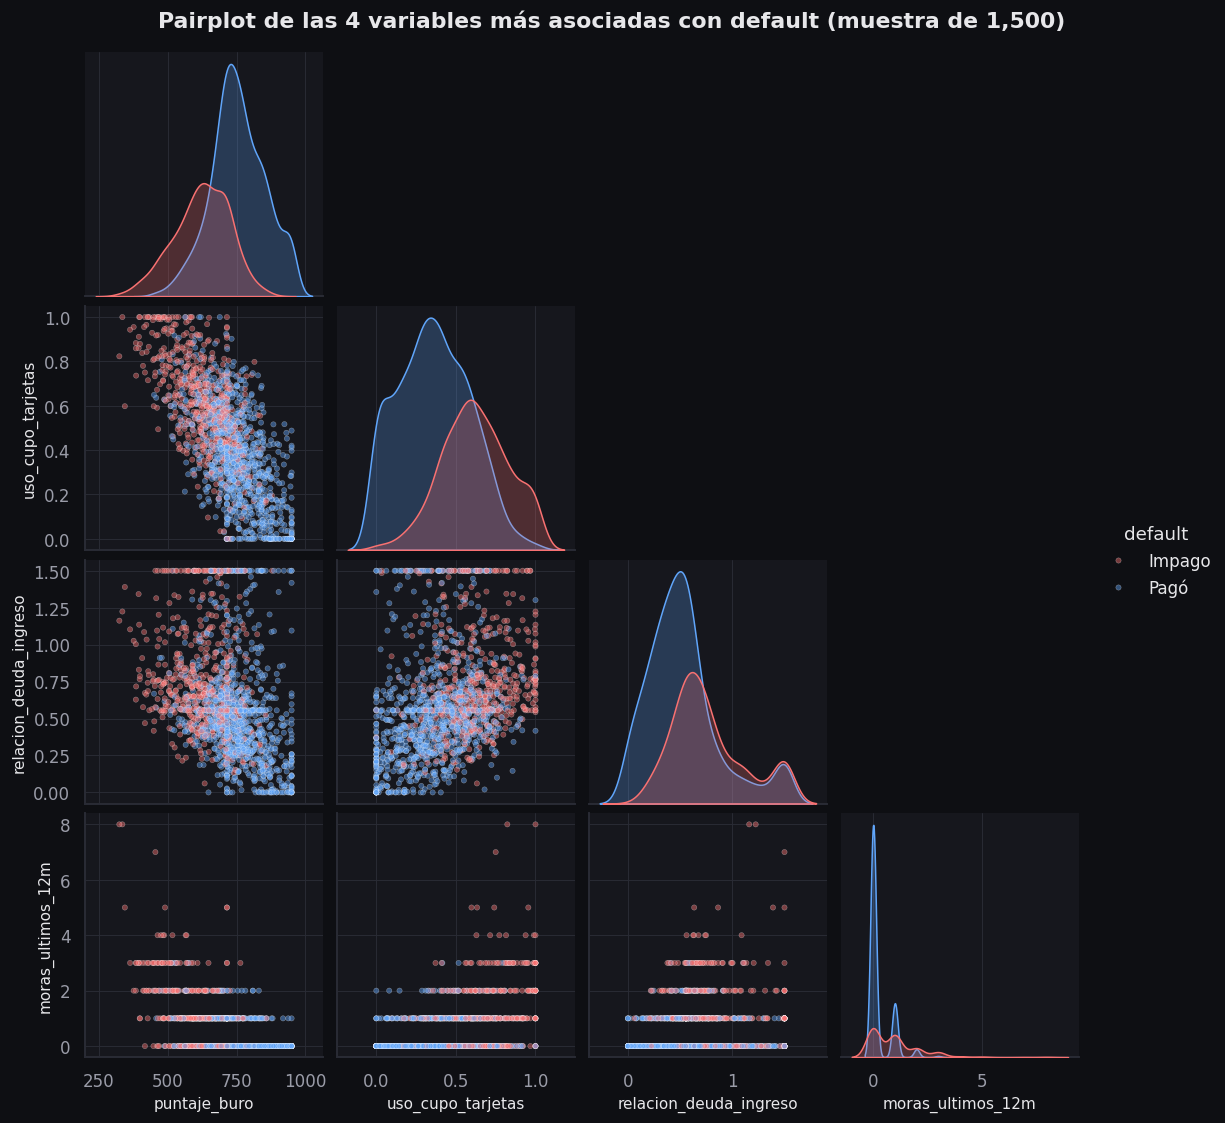

In [25]:
VARS_PAR = ["puntaje_buro", "uso_cupo_tarjetas", "relacion_deuda_ingreso", "moras_ultimos_12m"]
muestra_par = df[VARS_PAR + [T]].sample(min(1500, len(df)), random_state=config.RANDOM_STATE)
g = sns.pairplot(muestra_par.assign(**{T: muestra_par[T].map(ETIQUETA)}), hue=T, corner=True,
                 palette={"Pagó": PALETA["pago"], "Impago": PALETA["impago"]}, plot_kws={"alpha": 0.45, "s": 12},
                 diag_kind="kde")
g.figure.suptitle(f"Pairplot de las 4 variables más asociadas con default (muestra de {len(muestra_par):,})",
                  y=1.02, fontweight="bold")
plt.show()
for x, y in [("puntaje_buro", "uso_cupo_tarjetas"), ("puntaje_buro", "relacion_deuda_ingreso"),
             ("uso_cupo_tarjetas", "relacion_deuda_ingreso")]:
    figura_front("dispersion", f"{y} frente a {x} por clase",
                 {"series": [{"nombre": ETIQUETA[k], "puntos": [r4(p) for p in muestra_par.loc[muestra_par[T] == k, [x, y]].to_numpy()]}
                             for k in (0, 1)]},
                 ejes={"x": x, "y": y}, clave=f"sns_pairplot_{x}_{y}")

**Interpretación.** Ninguna variable separa por sí sola las clases: las densidades de la diagonal se
solapan. En los planos buró-uso del cupo y buró-deuda/ingreso los impagos se concentran en la zona de buró bajo y
uso o endeudamiento altos, y los pagadores en la opuesta: la combinación de variables discrimina mejor que
cualquiera de ellas sola.

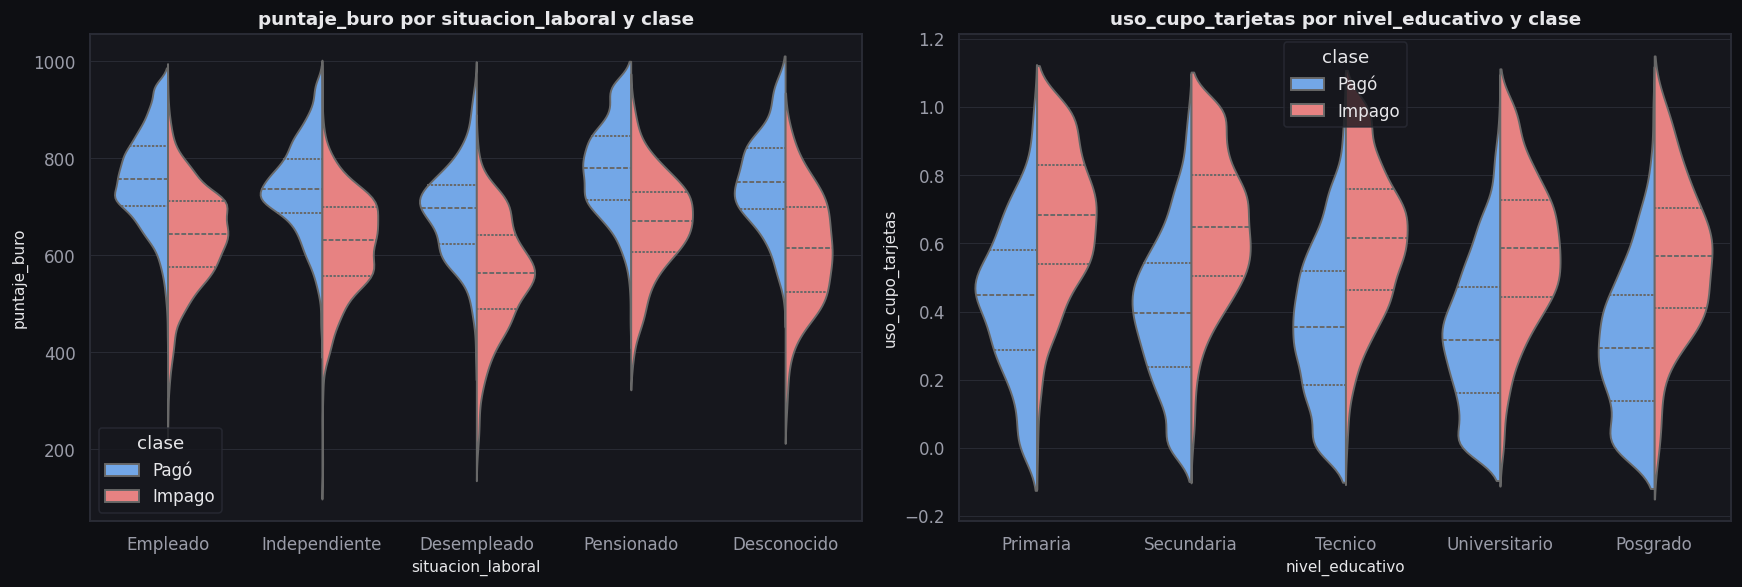

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (cat, var, orden) in zip(axes, [("situacion_laboral", "puntaje_buro", None),
                                        ("nivel_educativo", "uso_cupo_tarjetas", config.ORDINALES["nivel_educativo"])]):
    datos_v = df.assign(clase=df[T].map(ETIQUETA))
    sns.violinplot(data=datos_v, x=cat, y=var, hue="clase", split=True, inner="quart", order=orden,
                   palette={"Pagó": PALETA["pago"], "Impago": PALETA["impago"]}, ax=ax)
    ax.set(title=f"{var} por {cat} y clase", xlabel=cat, ylabel=var)
    cats = orden or list(datos_v[cat].drop_duplicates())
    figura_front("boxplot", f"{var} por {cat} y clase (cuartiles del violín)",
                 {"categorias": [str(c) for c in cats],
                  "series": [{"nombre": ETIQUETA[k], "cajas": [caja(df.loc[(df[cat] == c) & (df[T] == k), var]) for c in cats]}
                             for k in (0, 1)]},
                 ejes={"x": cat, "y": var}, clave=f"sns_violin_{var}_por_{cat}")
plt.show()

**Interpretación.** El efecto es **consistente entre segmentos**. En cada situación laboral los impagos
tienen un buró mediano más bajo (empleados 758 frente a 643, desempleados 697 frente a 565, pensionados 780 frente
a 670), y en cada nivel educativo un uso del cupo más alto (primaria 0,45 frente a 0,68, posgrado 0,29 frente a
0,56). Dentro de cada clase, el uso del cupo baja a medida que sube el nivel educativo.

### 3.3 La gramática de ggplot2 en Python con **plotnine**

`plotnine` implementa la gramática de gráficos de ggplot2: datos + estéticas (`aes`) + geometrías (`geom_*`)
+ facetas (`facet_wrap`) + tema. El código es prácticamente el mismo que en R
(`ggplot(df, aes(x, y)) + geom_boxplot() + facet_wrap(~situacion_laboral)`).

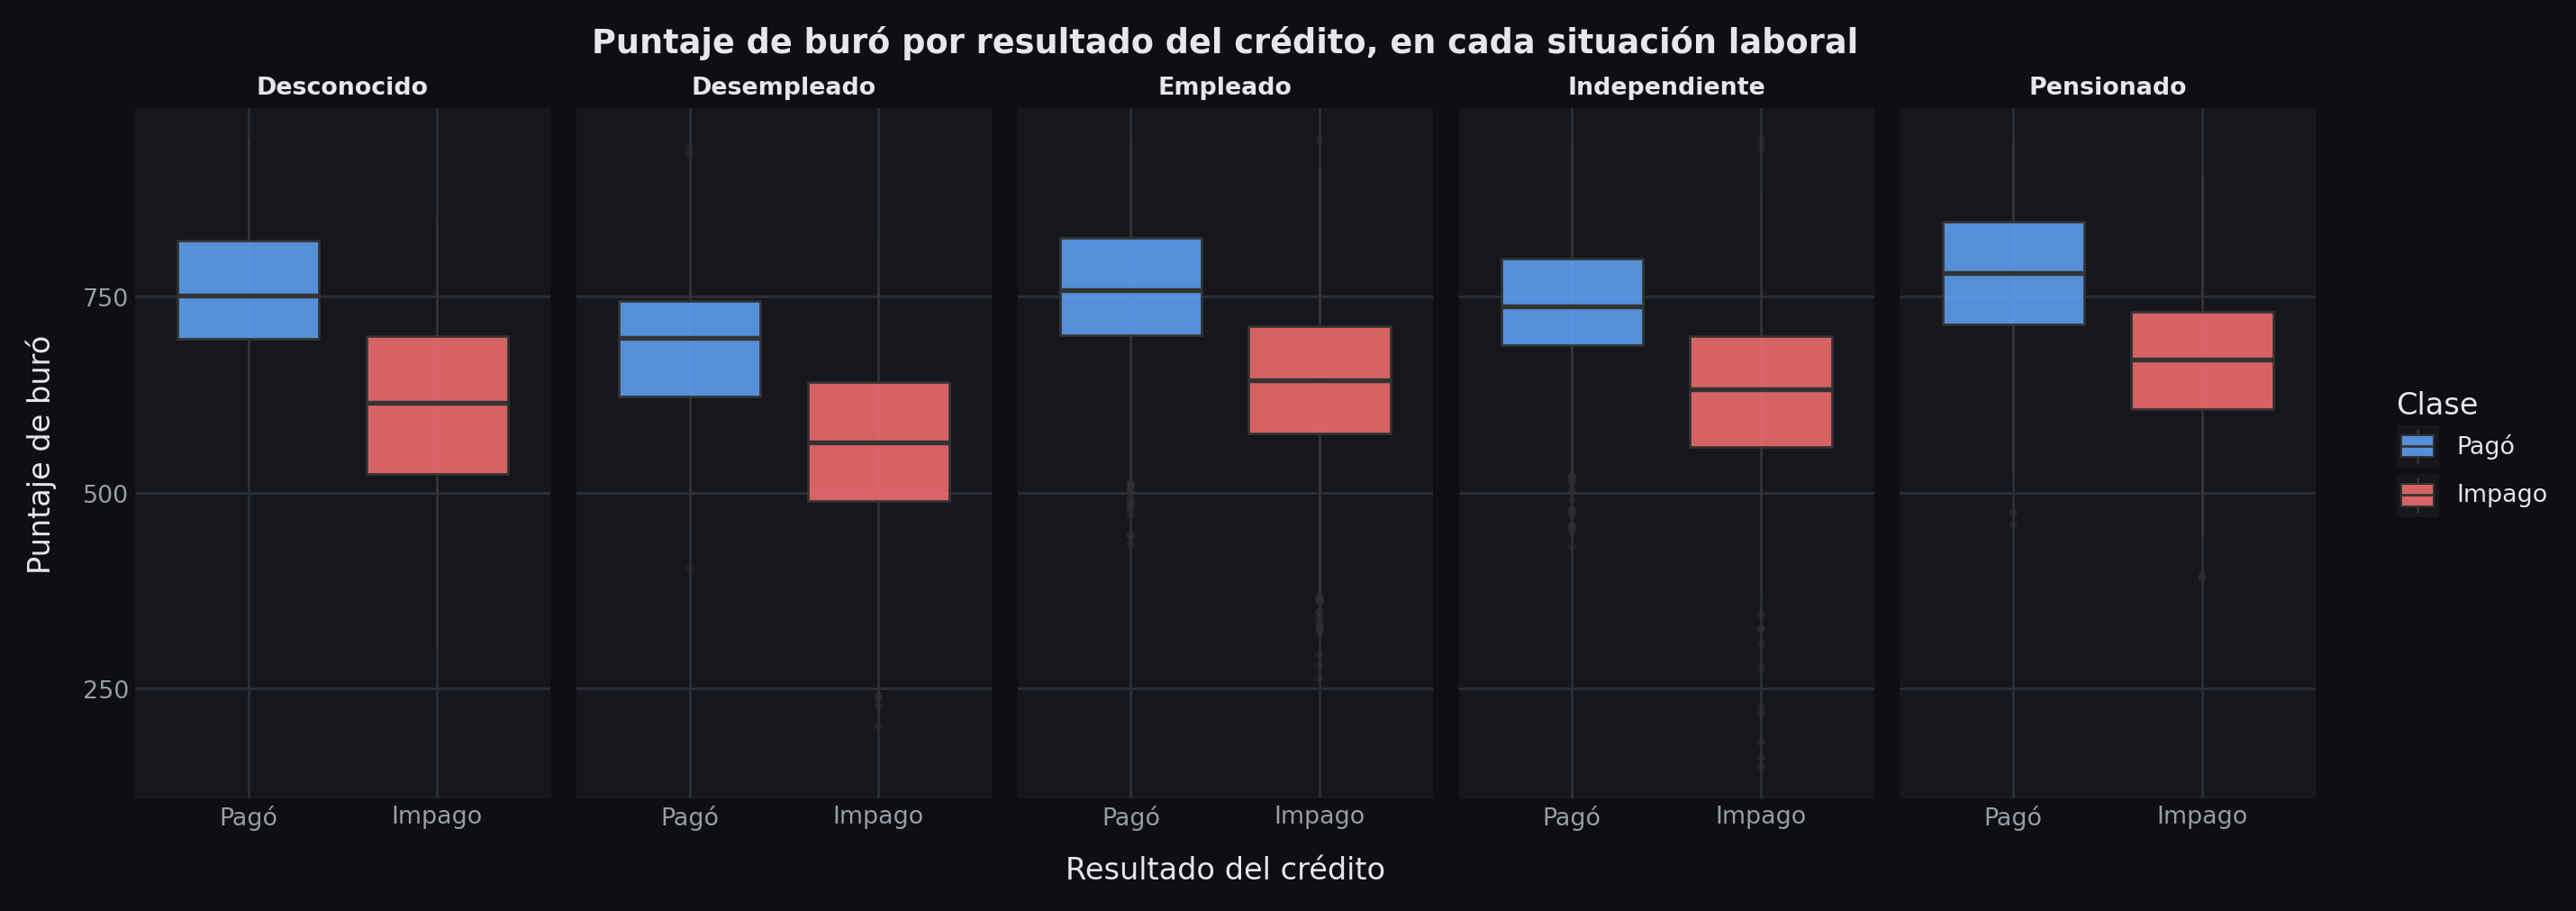

In [27]:
datos_gg = df.assign(clase=pd.Categorical(df[T].map(ETIQUETA), categories=["Pagó", "Impago"]))
p1 = (ggplot(datos_gg, aes(x="clase", y="puntaje_buro", fill="clase"))
      + geom_boxplot(alpha=0.85, outlier_alpha=0.3, outlier_size=0.8)
      + facet_wrap("~situacion_laboral", ncol=5)
      + scale_fill_manual(values=[PALETA["pago"], PALETA["impago"]])
      + labs(title="Puntaje de buró por resultado del crédito, en cada situación laboral", x="Resultado del crédito",
             y="Puntaje de buró", fill="Clase")
      + tema_plotnine() + theme(figure_size=(13, 4.6)))
p1.show()
sit = sorted(df["situacion_laboral"].unique())
figura_front("boxplot", "Puntaje de buró por clase en cada situación laboral",
             {"categorias": sit, "series": [{"nombre": ETIQUETA[k], "cajas": [caja(df.loc[(df["situacion_laboral"] == s) & (df[T] == k), "puntaje_buro"]) for s in sit]}
                                            for k in (0, 1)]},
             ejes={"x": "Situación laboral", "y": "Puntaje de buró"}, clave="gg_buro_por_clase_y_laboral")

**Interpretación.** Con la gramática de ggplot2 la misma comparación se repite en cada faceta: en las
cinco situaciones laborales la mediana del buró de los impagos está entre 105 y 136 puntos por debajo de la de
los pagadores. La brecha no depende del segmento laboral.

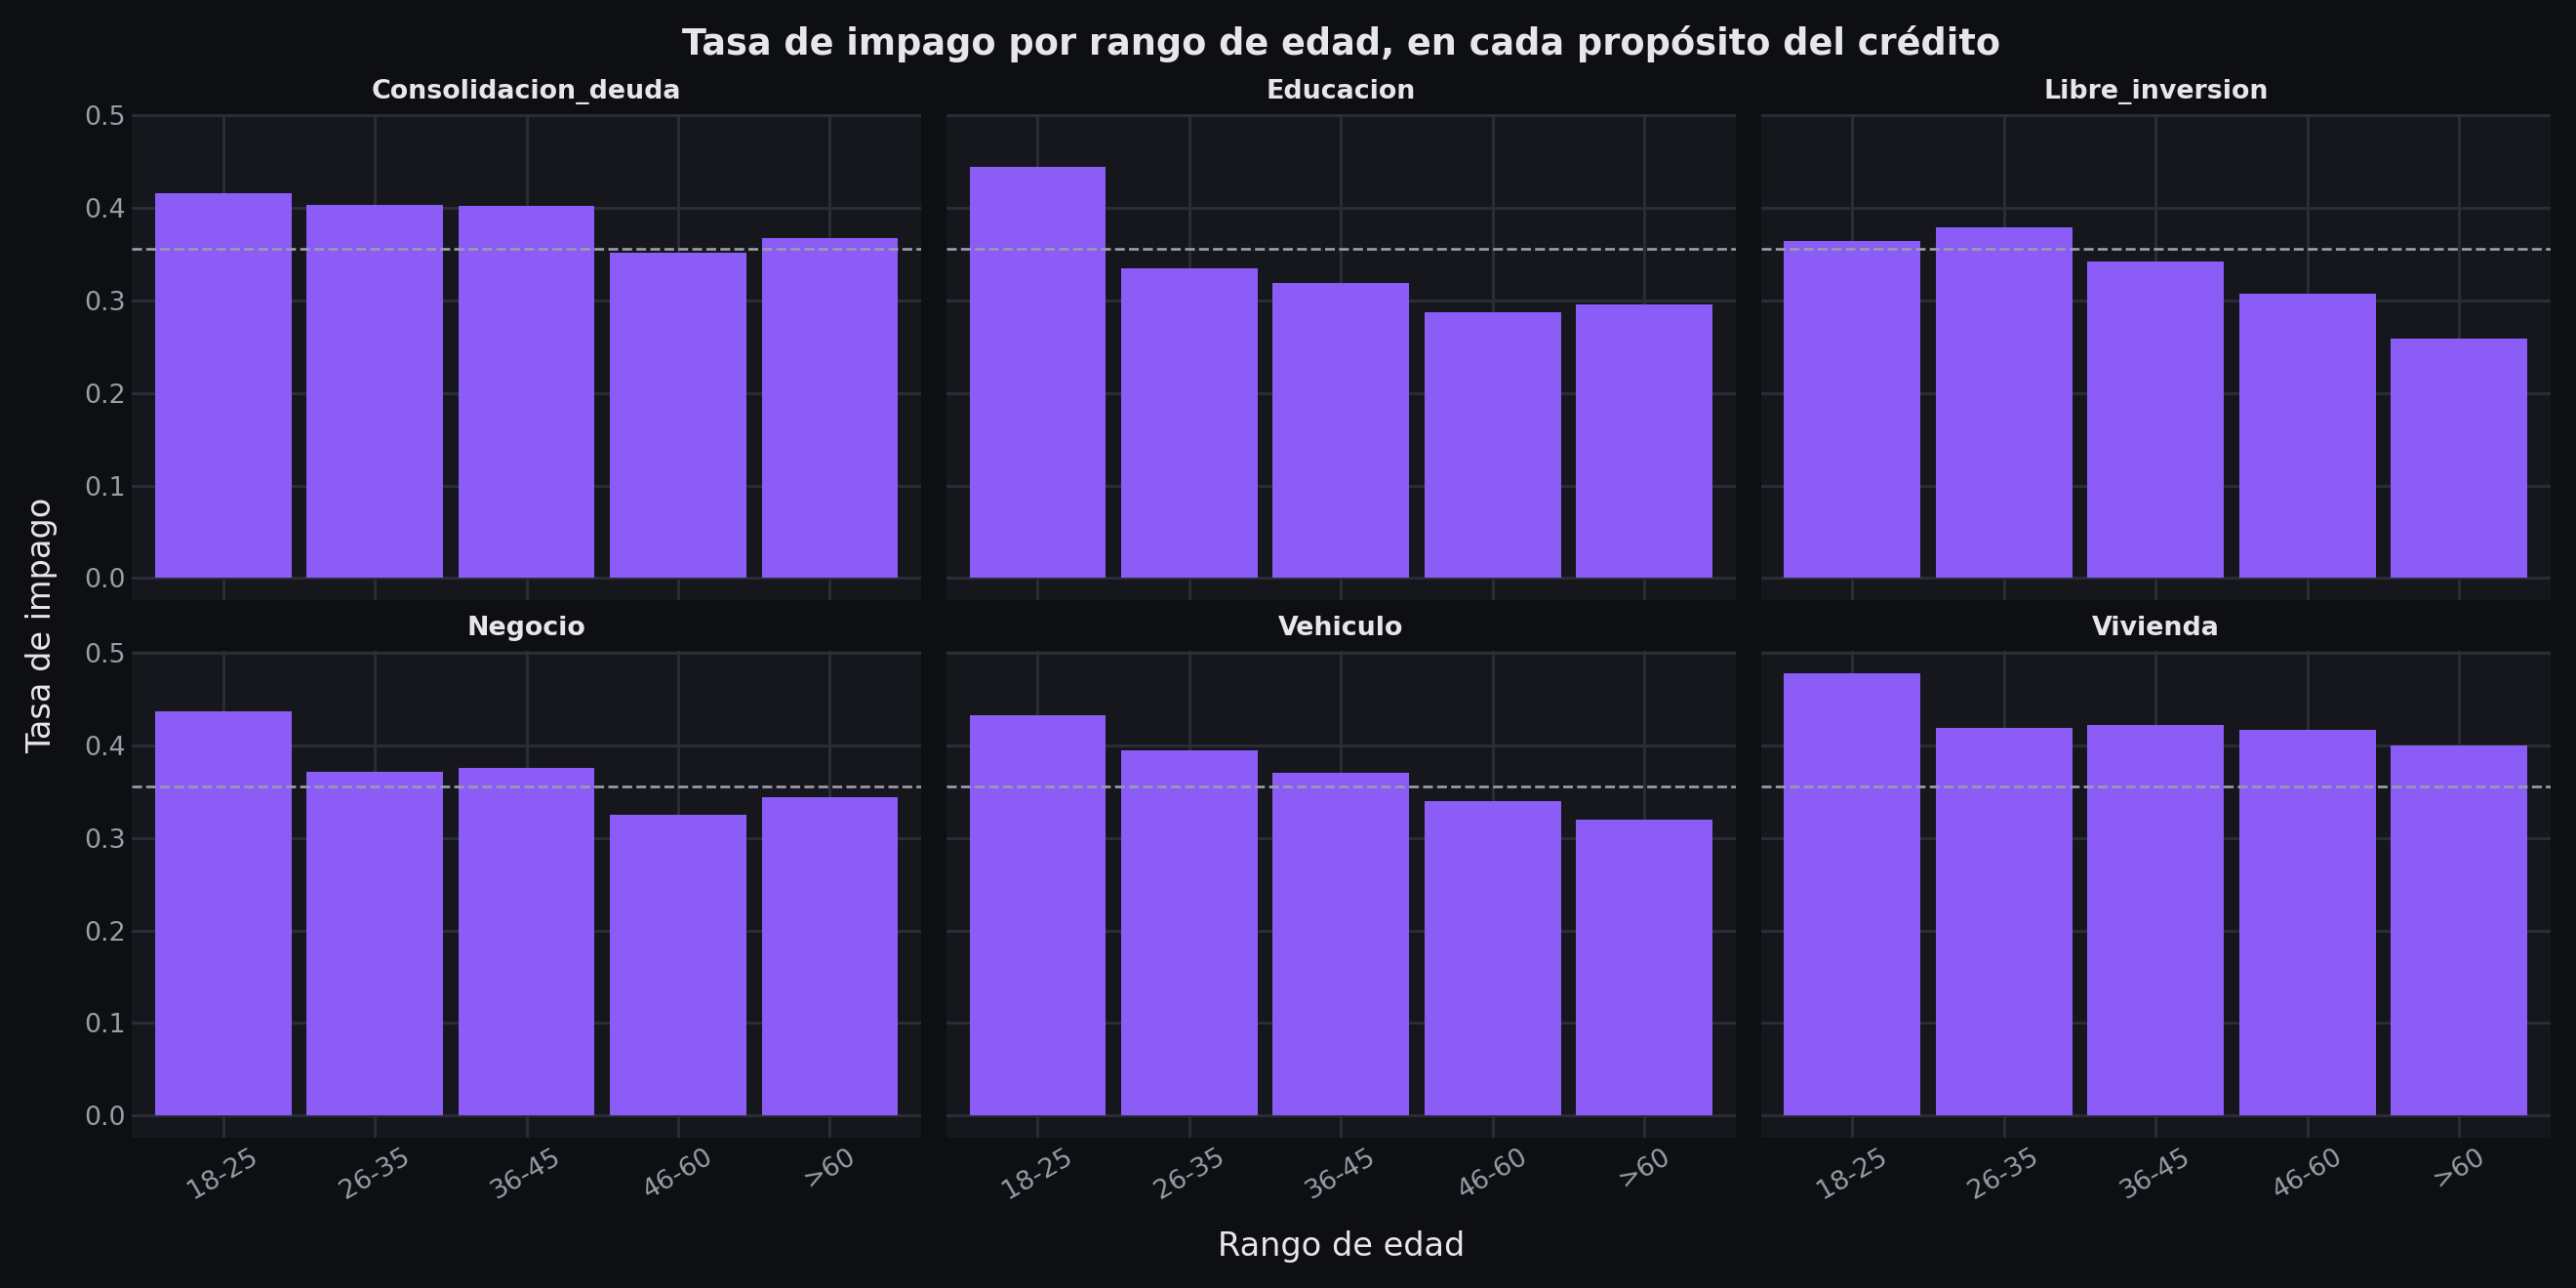

In [28]:
tasa_gg = (df.groupby(["proposito", "rango_edad"])[T].mean().reset_index(name="tasa_impago")
             .assign(rango_edad=lambda d: pd.Categorical(d["rango_edad"], categories=config.RANGO_EDAD_LABELS)))
p2 = (ggplot(tasa_gg, aes(x="rango_edad", y="tasa_impago"))
      + geom_col(fill=PALETA["ia"])
      + geom_hline(yintercept=TASA, linetype="dashed", color=PALETA["texto_suave"])
      + facet_wrap("~proposito", ncol=3)
      + labs(title="Tasa de impago por rango de edad, en cada propósito del crédito", x="Rango de edad",
             y="Tasa de impago")
      + tema_plotnine() + theme(figure_size=(12, 6), axis_text_x=element_text(rotation=30)))
p2.show()
piv_gg = tasa_gg.pivot(index="rango_edad", columns="proposito", values="tasa_impago").reindex(config.RANGO_EDAD_LABELS)
figura_front("barras", "Tasa de impago por rango de edad y propósito",
             {"categorias": config.RANGO_EDAD_LABELS,
              "series": [{"nombre": p, "valores": r4(piv_gg[p].values)} for p in piv_gg.columns],
              "referencias": [{"eje": "y", "valor": round(float(TASA), 4), "etiqueta": "tasa global"}]},
             ejes={"x": "Rango de edad", "y": "Tasa de impago"}, clave="gg_impago_edad_por_proposito",
             opciones={"formato_y": "pct", "facetas": "series"})

**Interpretación.** En los seis propósitos el impago del rango 18-25 supera al de >60 (por ejemplo, educación
44,4 % frente a 29,6 % y vehículo 43,3 % frente a 32,0 %), aunque el descenso con la edad no es perfectamente
monótono: en libre inversión el máximo está en 26-35 (37,9 %). El crédito de vivienda queda por encima de la tasa
global en todas las edades (entre 40,0 % y 47,8 %).

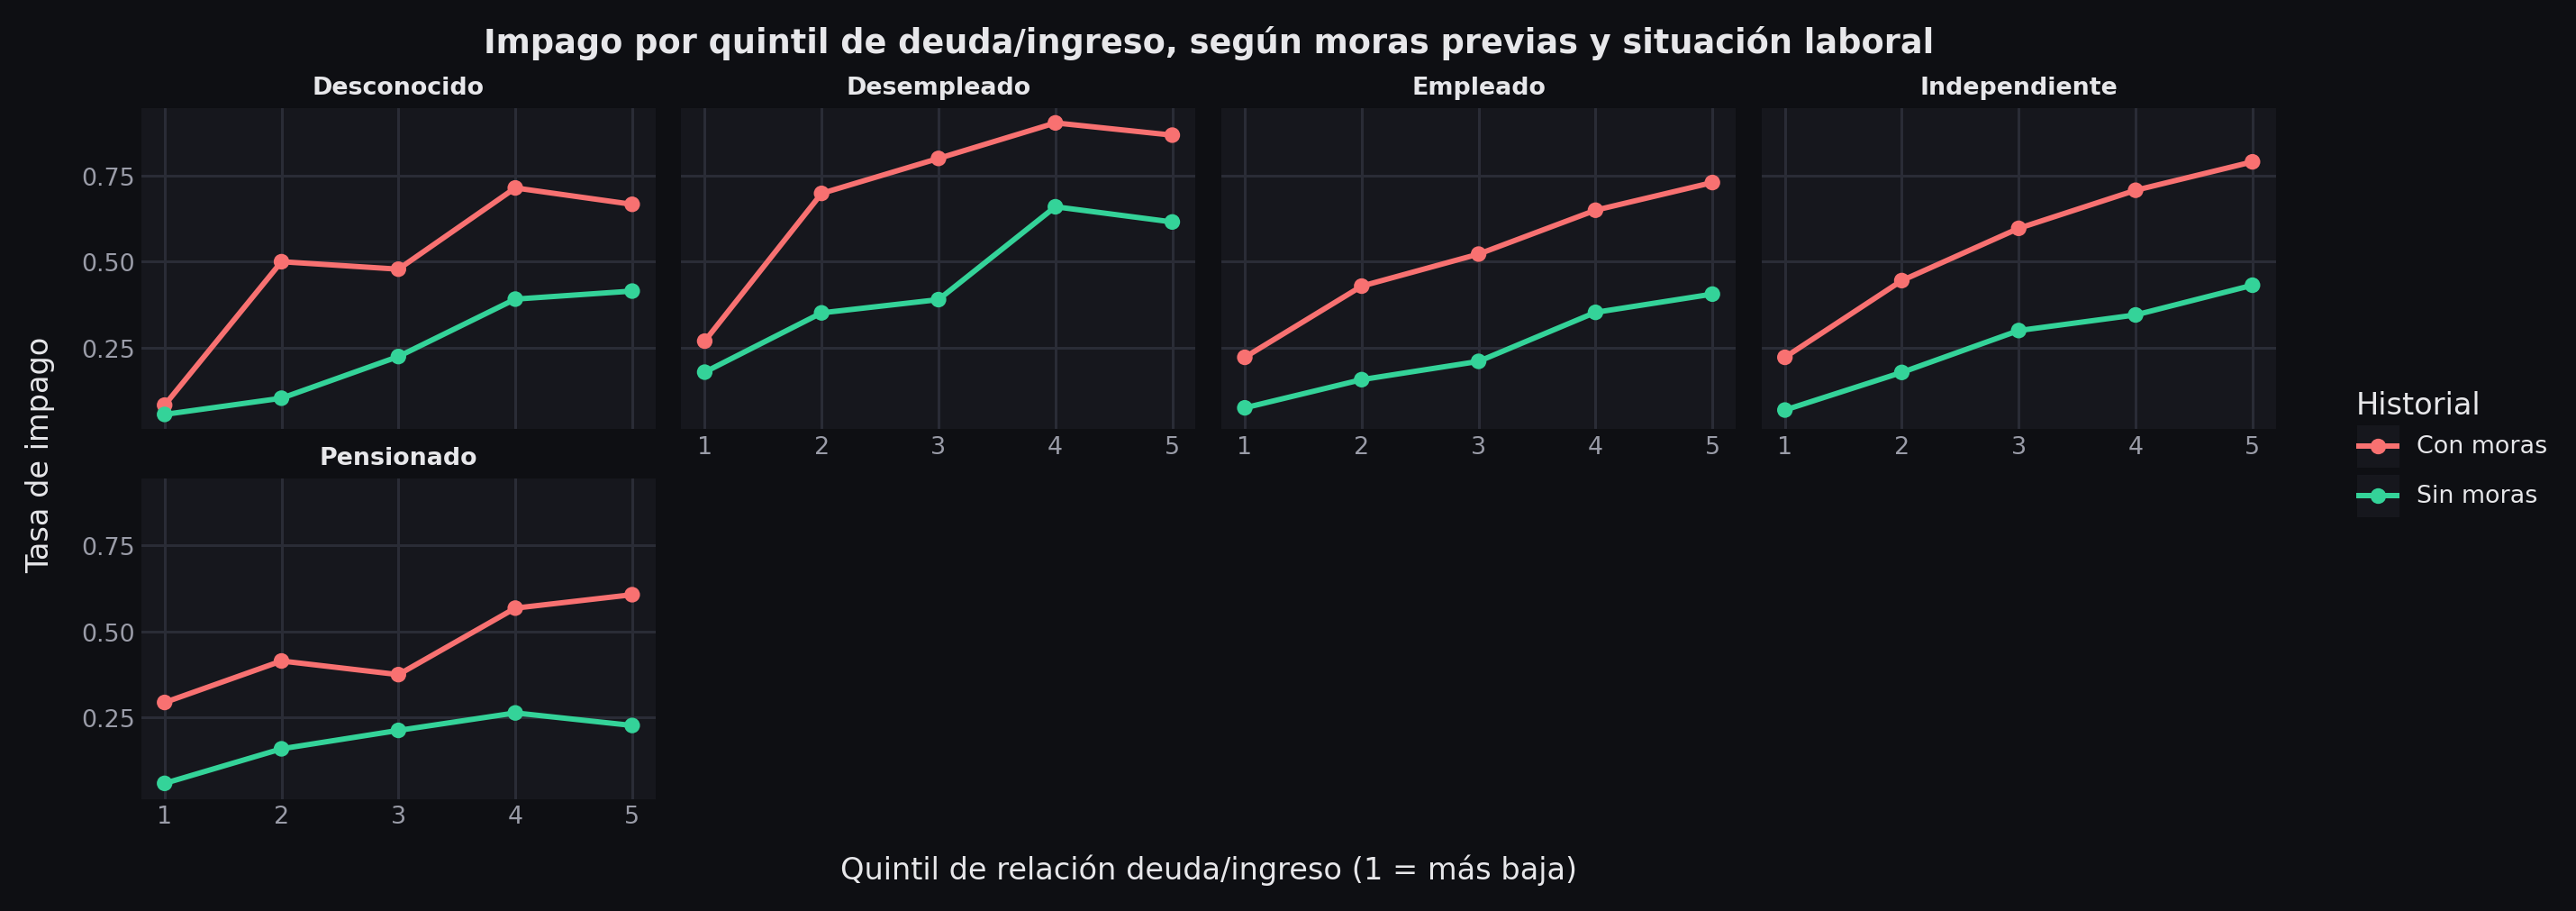

In [29]:
tasa_dti = (df.assign(quintil_dti=pd.qcut(df["relacion_deuda_ingreso"], 5, labels=False) + 1,
                      moras=np.where(df["tiene_moras_previas"] == 1, "Con moras", "Sin moras"))
              .groupby(["situacion_laboral", "moras", "quintil_dti"])[T].mean().reset_index(name="tasa_impago"))
p3 = (ggplot(tasa_dti, aes(x="quintil_dti", y="tasa_impago", color="moras", group="moras"))
      + geom_line(size=1.1) + geom_point(size=2.2)
      + facet_wrap("~situacion_laboral", ncol=4)
      + scale_color_manual(values={"Sin moras": PALETA["bajo"], "Con moras": PALETA["alto"]})
      + labs(title="Impago por quintil de deuda/ingreso, según moras previas y situación laboral",
             x="Quintil de relación deuda/ingreso (1 = más baja)", y="Tasa de impago", color="Historial")
      + tema_plotnine() + theme(figure_size=(13, 4.6)))
p3.show()
figura_front("lineas", "Impago por quintil de deuda/ingreso, según moras previas y situación laboral",
             {"series": [{"nombre": f"{s} · {m}", "x": g_["quintil_dti"].tolist(), "y": r4(g_["tasa_impago"])}
                         for (s, m), g_ in tasa_dti.groupby(["situacion_laboral", "moras"])]},
             ejes={"x": "Quintil de relación deuda/ingreso", "y": "Tasa de impago"}, clave="gg_impago_dti_moras_laboral",
             opciones={"formato_y": "pct", "facetas": "situacion_laboral"})

**Interpretación.** En las cinco situaciones laborales el impago sube con el quintil de deuda/ingreso, y en
cada quintil la curva "Con moras" está por encima de "Sin moras". Un empleado sin moras pasa de ≈ 7,5 % (quintil 1)
a 40,6 % (quintil 5); con moras, de 22,2 % a 73,0 %. Los desempleados con moras alcanzan el 80 % en el quintil
3. Las curvas no son perfectamente monótonas en grupos pequeños ("Desconocido", pensionados), pero el patrón se
repite: **endeudamiento e historial de moras se suman**.

## 4. IA2.E1 · Patrones y correlaciones
### 4.1 Pearson frente a Spearman con el objetivo

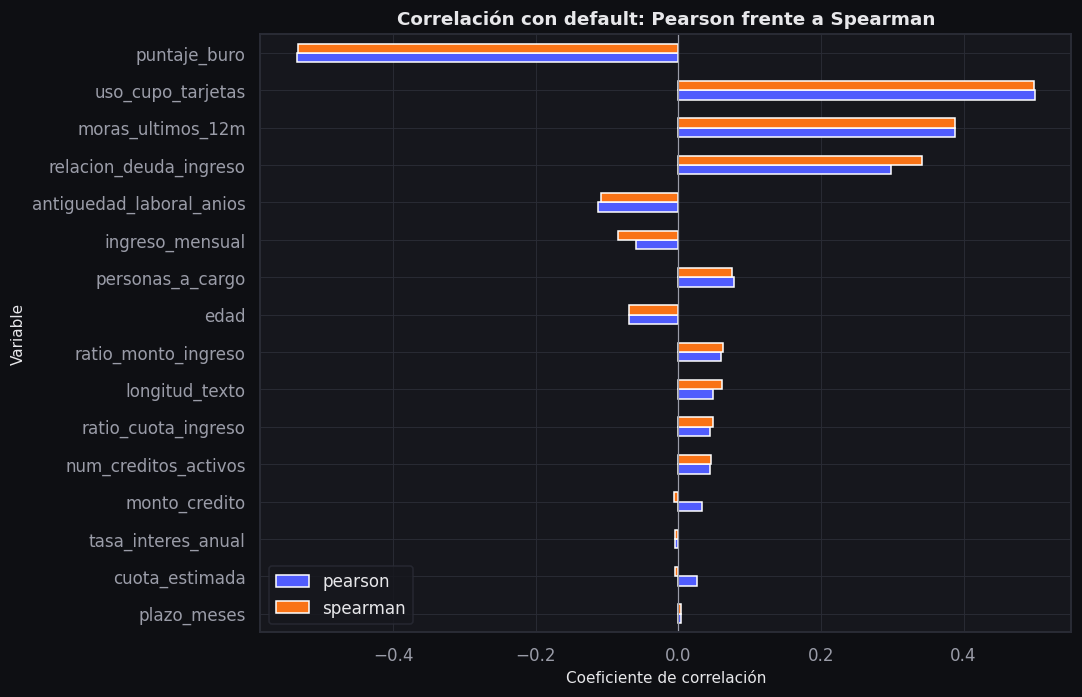

,pearson,spearman,diferencia
puntaje_buro,-0.5340,-0.5330,0.0010
uso_cupo_tarjetas,0.4990,0.4990,0.0010
moras_ultimos_12m,0.3880,0.3870,0.0010
relacion_deuda_ingreso,0.2990,0.3410,0.0430
antiguedad_laboral_anios,-0.1120,-0.1080,0.0040
ingreso_mensual,-0.0590,-0.0840,0.0250
personas_a_cargo,0.0770,0.0750,0.0030
edad,-0.0690,-0.0690,0.0000
ratio_monto_ingreso,0.0600,0.0620,0.0020
longitud_texto,0.0490,0.0610,0.0120


In [30]:
corr_obj = pd.DataFrame({"pearson": df[NUM].corrwith(df[T], method="pearson"),
                         "spearman": df[NUM].corrwith(df[T], method="spearman")})
corr_obj["diferencia"] = (corr_obj["spearman"] - corr_obj["pearson"]).abs()
corr_obj = corr_obj.reindex(corr_obj["spearman"].abs().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(10, 6.5))
corr_obj[["pearson", "spearman"]].iloc[::-1].plot.barh(ax=ax, color=[PALETA["acento"], PALETA["programacion"]])
ax.axvline(0, color=PALETA["texto_suave"], lw=0.8)
ax.set(title="Correlación con default: Pearson frente a Spearman", xlabel="Coeficiente de correlación", ylabel="Variable")
plt.show()
figura_front("barras_h", "Correlación con default: Pearson frente a Spearman",
             {"categorias": list(corr_obj.index), "series": [{"nombre": "Pearson", "valores": r4(corr_obj["pearson"])},
                                                             {"nombre": "Spearman", "valores": r4(corr_obj["spearman"])}]},
             ejes={"x": "Coeficiente de correlación", "y": "Variable"}, clave="correlacion_pearson_spearman")
corr_obj.round(3)

**Interpretación.** En las variables acotadas (buró, uso del cupo, moras) Pearson y Spearman coinciden. En
las monetarias difieren: `relacion_deuda_ingreso` (0,30 frente a 0,34), `ingreso_mensual` (−0,06 frente a
−0,08) y sobre todo `monto_credito` (0,034 frente a −0,006) y `cuota_estimada` (0,027 frente a −0,004), cuyo
Pearson positivo lo producen unos pocos valores extremos. Pearson se distorsiona con los atípicos; Spearman,
basado en rangos, no. `tasa_interes_anual` y `plazo_meses` tienen correlación ≈ 0 con ambos métodos.

### 4.2 V de Cramér: categóricas frente a `default`

La V de Cramér mide la asociación entre dos variables categóricas a partir del χ² (0 = ninguna, 1 = total).
Se usa la versión con corrección de sesgo de Bergsma (2013), que no infla la asociación en tablas grandes.

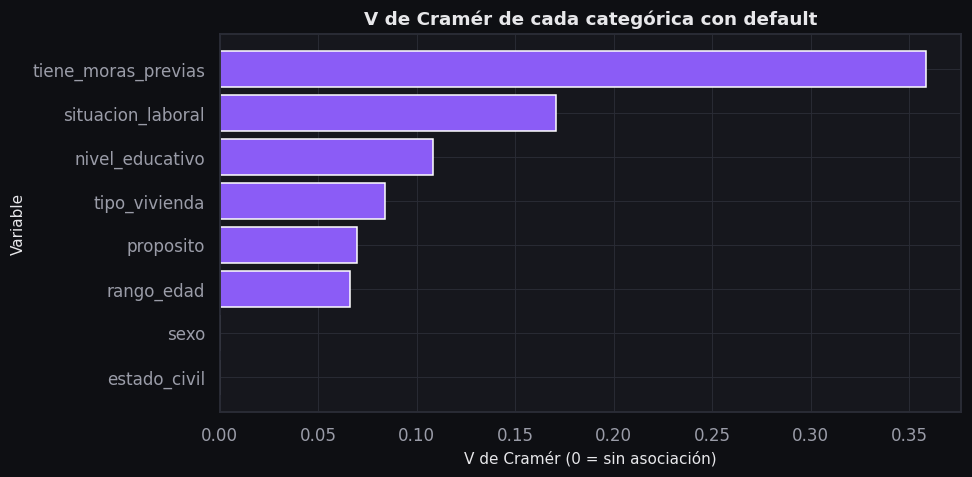

,v_cramer,p_valor_chi2
tiene_moras_previas,0.3586,0.0000
situacion_laboral,0.1709,0.0000
nivel_educativo,0.1082,0.0000
tipo_vivienda,0.0838,0.0000
proposito,0.0700,0.0000
rango_edad,0.0662,0.0000
sexo,0.0000,0.6737
estado_civil,0.0000,0.4387


In [31]:
def v_cramer(x: pd.Series, y: pd.Series) -> float:
    """V de Cramér con corrección de sesgo (Bergsma, 2013)."""
    tabla = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1))))


cramer = pd.DataFrame({"v_cramer": {c: v_cramer(df[c], df[T]) for c in CAT},
                       "p_valor_chi2": {c: stats.chi2_contingency(pd.crosstab(df[c], df[T]))[1] for c in CAT}}
                      ).sort_values("v_cramer", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(cramer.index[::-1], cramer["v_cramer"][::-1], color=PALETA["ia"])
ax.set(title="V de Cramér de cada categórica con default", xlabel="V de Cramér (0 = sin asociación)", ylabel="Variable")
plt.show()
figura_front("barras_h", "V de Cramér de cada categórica con default",
             {"categorias": list(cramer.index), "series": [{"nombre": "V de Cramér", "valores": r4(cramer["v_cramer"])}]},
             ejes={"x": "V de Cramér (0 = sin asociación)", "y": "Variable"}, clave="v_cramer_categoricas")
cramer.round(4)

**Interpretación.** La asociación categórica más fuerte es la de `tiene_moras_previas` (V = 0,359), seguida
de `situacion_laboral` (0,171), `nivel_educativo` (0,108), `tipo_vivienda` (0,084), `proposito` (0,070) y
`rango_edad` (0,066), todas con p < 0,0001. `sexo` y `estado_civil` tienen V = 0 y p = 0,67 y 0,44: no hay
evidencia de asociación con el impago.

### 4.3 Cinco hallazgos e hipótesis

1. **El historial crediticio domina el riesgo.** `puntaje_buro` (Spearman −0,53) y las moras (0,39) son
   las variables más asociadas al impago. Los clientes con buró < 600 son el 17 % de la cartera y el 39 % de los
   impagos. *Hipótesis:* el buró y las moras serán las variables de mayor peso en cualquier modelo.
2. **El uso del cupo y el endeudamiento anticipan el impago.** El impago pasa de 4,3 % a 81,7 % entre deciles
   de uso del cupo y crece con la relación deuda/ingreso en todas las situaciones laborales. *Hipótesis:* su
   relación es monótona, así que un modelo lineal la capta bien.
3. **La estabilidad protege.** Desempleados 62,3 % frente a pensionados 23,7 %; primaria 45,2 % frente a
   posgrado 26,3 %; arriendo 39,5 % frente a vivienda propia 30,6 %. *Hipótesis:* aportan información
   adicional al historial, con menor peso.
4. **Las condiciones del crédito no discriminan por sí solas.** Monto, plazo, tasa y cuota no difieren entre
   clases (Mann-Whitney, p > 0,5; |Spearman| < 0,01). Su información aparece al relacionarlas con el ingreso
   (ratios) y de forma no lineal (la U de la cuota en el paso 3). *Hipótesis:* un modelo de árboles podría
   aprovecharlas un poco más que la regresión logística.
5. **Las variables sensibles aportan poco, salvo la edad.** `sexo` y `estado_civil` tienen V de Cramér = 0:
   excluir `sexo` no cuesta información. La edad sí tiene efecto (41,9 % en 18-25 frente a 32,3 % en >60).
   *Hipótesis:* un modelo con edad puede aprobar menos a los jóvenes; se audita con el *disparate impact* en el
   paso 8.

## 5. IA2.5 · Valores atípicos
### 5.1 Detección con IQR (1,5·IQR) y z-score (|z| > 3)

In [32]:
CONT = [c for c in NUM if c not in ("personas_a_cargo", "plazo_meses", "longitud_texto")]
iqr_mask = {}
for c in CONT:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr_mask[c] = (df[c] < q1 - 1.5 * (q3 - q1)) | (df[c] > q3 + 1.5 * (q3 - q1))
deteccion = pd.DataFrame({"atipicos_IQR": {c: int(m.sum()) for c, m in iqr_mask.items()},
                          "atipicos_z>3": {c: int((np.abs(stats.zscore(df[c])) > 3).sum()) for c in CONT}})
deteccion["pct_IQR"] = deteccion["atipicos_IQR"] / len(df) * 100
deteccion["pct_z"] = deteccion["atipicos_z>3"] / len(df) * 100
deteccion["en_capping"] = deteccion.index.isin(config.COLS_CAPPING)
deteccion.sort_values("atipicos_IQR", ascending=False).round(2)

,atipicos_IQR,atipicos_z>3,pct_IQR,pct_z,en_capping
ratio_monto_ingreso,1126,168,11.7300,1.7500,True
ratio_cuota_ingreso,982,200,10.2300,2.0800,True
cuota_estimada,966,156,10.0600,1.6200,True
monto_credito,939,165,9.7800,1.7200,True
num_creditos_activos,734,60,7.6500,0.6200,False
relacion_deuda_ingreso,700,0,7.2900,0.0000,True
ingreso_mensual,446,69,4.6500,0.7200,True
antiguedad_laboral_anios,441,112,4.5900,1.1700,True
moras_ultimos_12m,383,136,3.9900,1.4200,False
puntaje_buro,119,40,1.2400,0.4200,False


**Lectura.** IQR marca muchos más atípicos que el z-score en las variables asimétricas
(`ratio_monto_ingreso` 11,7 % frente a 1,8 %; `monto_credito` 9,8 % frente a 1,7 %) porque su cola derecha es larga
por naturaleza; el z-score (|z| > 3) es más conservador. En `relacion_deuda_ingreso`, IQR marca 7,3 % y el
z-score 0 %: son los valores acumulados en el tope de 1,5. En `moras_ultimos_12m` y `num_creditos_activos` los
"atípicos" son valores altos legítimos (clientes con muchas moras o créditos), no errores, y por eso no se
recortan.

### 5.2 ¿Por qué no eliminar filas?

Se mide qué pasaría si se eliminaran las filas con algún atípico IQR en las variables que se tratan.

In [33]:
alguna = pd.concat([iqr_mask[c] for c in config.COLS_CAPPING if c in iqr_mask], axis=1).any(axis=1)
impacto = pd.DataFrame({"filas": [len(df), int(alguna.sum()), int((~alguna).sum())],
                        "tasa_impago": [df[T].mean(), df.loc[alguna, T].mean(), df.loc[~alguna, T].mean()]},
                       index=["train completo", "filas con algún atípico IQR", "train si se eliminaran"])
impacto["pct_de_train"] = impacto["filas"] / len(df) * 100
impacto.round(4)

,filas,tasa_impago,pct_de_train
train completo,9600,0.3556,100.0000
filas con algún atípico IQR,2286,0.3613,23.8125
train si se eliminaran,7314,0.3538,76.1875


**Lectura.** Eliminar las filas con algún atípico IQR en las variables tratadas borraría
**2.286 clientes, el 23,8 % de train**. Su tasa de impago (36,1 %) es casi la misma del resto (35,4 %): no son
errores concentrados en una clase, sino clientes reales con valores extremos y el resto de columnas válidas.
Además, la API recibirá clientes así y el modelo debe poder puntuarlos. Por eso se recorta (*capping*) en lugar de
eliminar.

### 5.3 Tratamiento: *capping* p1-p99 con `Winsorizer` ajustado en train

`credit_risk.features.Winsorizer` aprende los percentiles 1 y 99 **en train** (`fit`) y recorta (`transform`)
cualquier conjunto con esos mismos límites. Es el paso `capping` del pipeline servido, así que la API trata
los atípicos exactamente igual.

In [34]:
winsor = Winsorizer().fit(train_completo)
limites_nb03 = leer_json(config.PROCESSED_DIR / "limites_atipicos.json")["limites"]
assert all(np.allclose(winsor.limites_[c], limites_nb03[c]) for c in winsor.limites_)
print(f"✔ Límites idénticos a {ruta(config.PROCESSED_DIR / 'limites_atipicos.json')} (escritos en el paso 3)")
df_cap = winsor.transform(df)
_, test_df = cargar_procesados()
test_cap = winsor.transform(test_df)
cap = config.COLS_CAPPING
tratamiento = pd.DataFrame({
    "p1": {c: winsor.limites_[c][0] for c in cap}, "p99": {c: winsor.limites_[c][1] for c in cap},
    "max_antes": df[cap].max(), "max_despues": df_cap[cap].max(),
    "asimetria_antes": df[cap].skew(), "asimetria_despues": df_cap[cap].skew(),
    "filas_recortadas_train": (df[cap] != df_cap[cap]).sum(),
    "filas_recortadas_test": (test_df[cap] != test_cap[cap]).sum(),
})
tratamiento.round(2)

✔ Límites idénticos a db/processed/limites_atipicos.json (escritos en el paso 3)


,p1,p99,max_antes,max_despues,asimetria_antes,asimetria_despues,filas_recortadas_train,filas_recortadas_test
ingreso_mensual,"578,000.0000","7,816,150.0000","64,540,000.0000","7,816,150.0000",10.8100,1.4400,191,57
monto_credito,"2,006,000.0000","144,522,390.0000","1,033,300,000.0000","144,522,390.0000",9.5400,2.8000,191,37
cuota_estimada,"76,469.6700","11,020,996.4000","78,233,341.9900","11,020,996.4000",9.7100,3.3800,192,33
ratio_cuota_ingreso,0.0500,3.5700,13.2000,3.5700,5.3700,2.9600,192,54
ratio_monto_ingreso,1.6400,37.7500,194.2300,37.7500,4.8100,2.1600,192,42
antiguedad_laboral_anios,0.0000,52.3000,62.0000,52.3000,1.3200,1.2700,95,27
relacion_deuda_ingreso,0.0000,1.5000,1.5000,1.5000,0.8800,0.8800,0,0


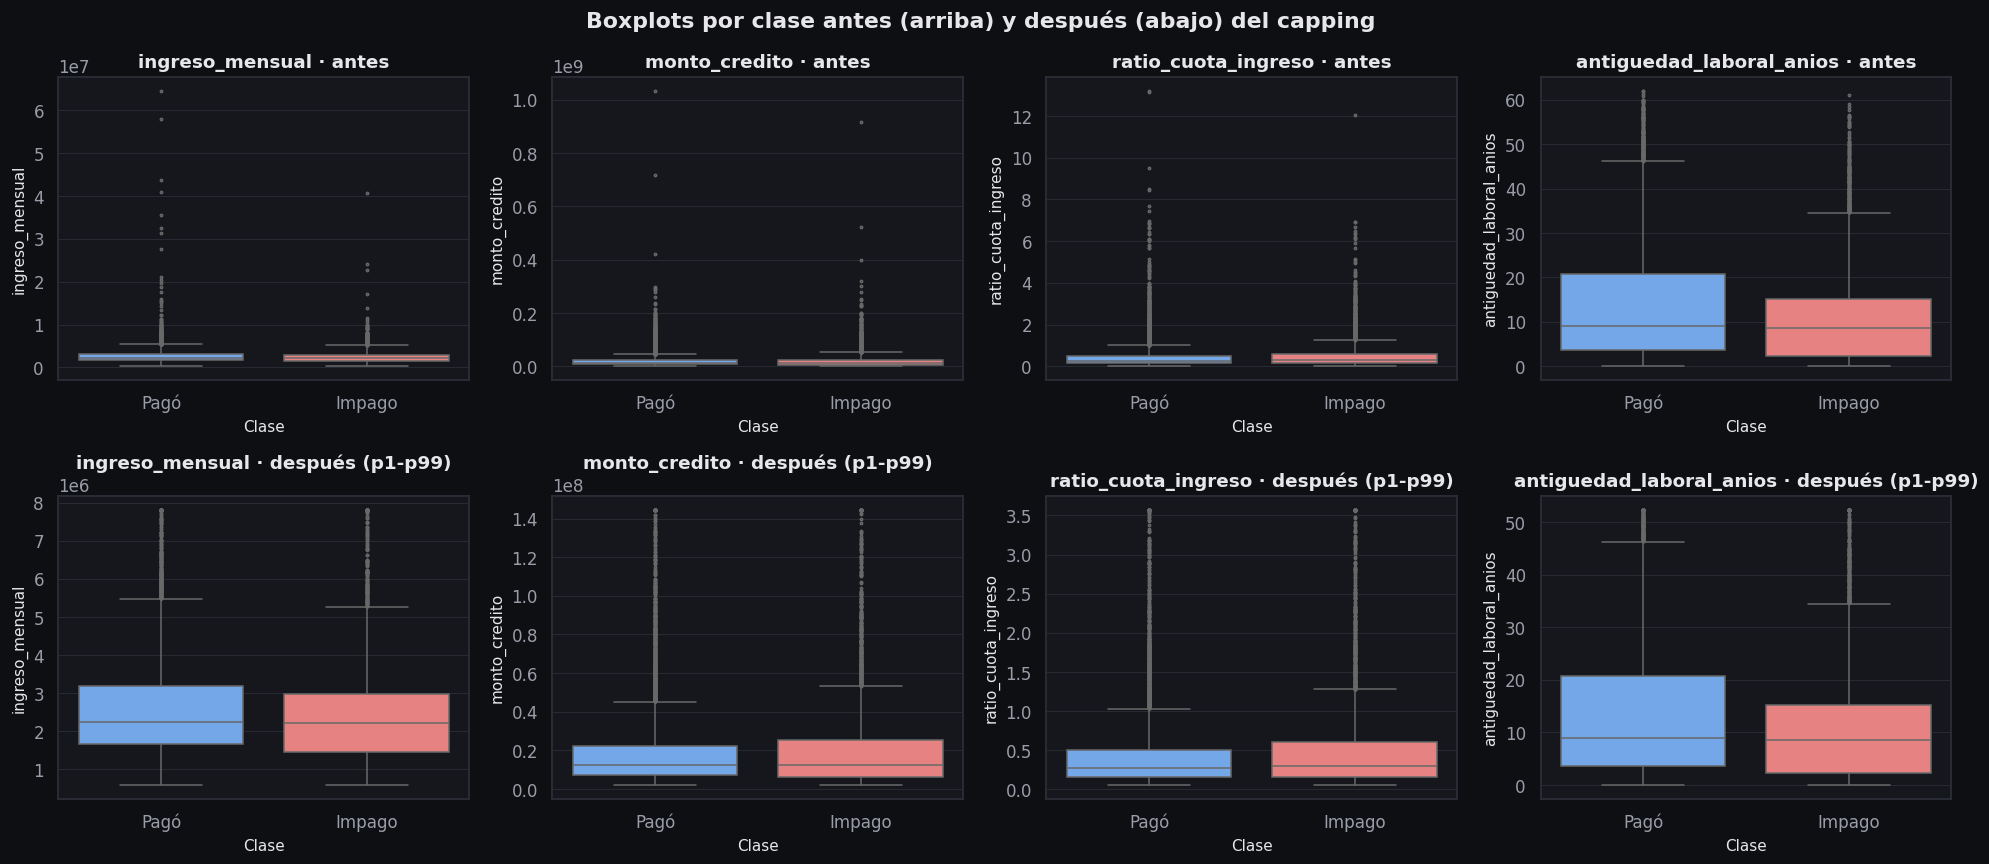

In [35]:
VARS_BOX = ["ingreso_mensual", "monto_credito", "ratio_cuota_ingreso", "antiguedad_laboral_anios"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, c in enumerate(VARS_BOX):
    for fila, (datos, momento) in enumerate([(df, "antes"), (df_cap, "después (p1-p99)")]):
        sns.boxplot(x=datos[T].map(ETIQUETA), y=datos[c], order=["Pagó", "Impago"], ax=axes[fila, i],
                    palette=[PALETA["pago"], PALETA["impago"]], fliersize=1.5)
        axes[fila, i].set(title=f"{c} · {momento}", xlabel="Clase", ylabel=c)
    figura_front("boxplot", f"{c}: antes y después del capping p1-p99",
                 {"categorias": ["Pagó", "Impago"],
                  "series": [{"nombre": nombre, "cajas": [caja(d.loc[d[T] == k, c]) for k in (0, 1)]}
                             for nombre, d in [("Antes", df), ("Después", df_cap)]]},
                 ejes={"x": "Clase", "y": c}, clave=f"capping_boxplot_{c}",
                 nota="Bigotes de Tukey (1,5·IQR); los puntos fuera de los bigotes son atípicos")
plt.suptitle("Boxplots por clase antes (arriba) y después (abajo) del capping", fontweight="bold")
plt.show()

**Interpretación.** La tabla y los boxplots muestran el efecto. El capping recorta unas 191-192 filas por
variable monetaria en train (2 %), 95 en `antiguedad_laboral_anios` y ninguna en `relacion_deuda_ingreso`, cuyos
p1 y p99 coinciden con sus límites (0 y 1,5); en test, con los límites de train, se recortan entre 27 y 57 filas
por variable. Los máximos extremos desaparecen (ingreso: de 64,5 millones a 7,8 millones) y la asimetría cae
(ingreso de 10,81 a 1,44; monto de 9,54 a 2,80). En los boxplots, cuartiles y medianas **no cambian**: solo se
mueven las colas (el bigote inferior sube hasta el p1). Las clases conservan su posición relativa: los impagos
tienen menos antigüedad (mediana 8,6 frente a 9,0) y una cuota/ingreso más alta (0,295 frente a 0,269).

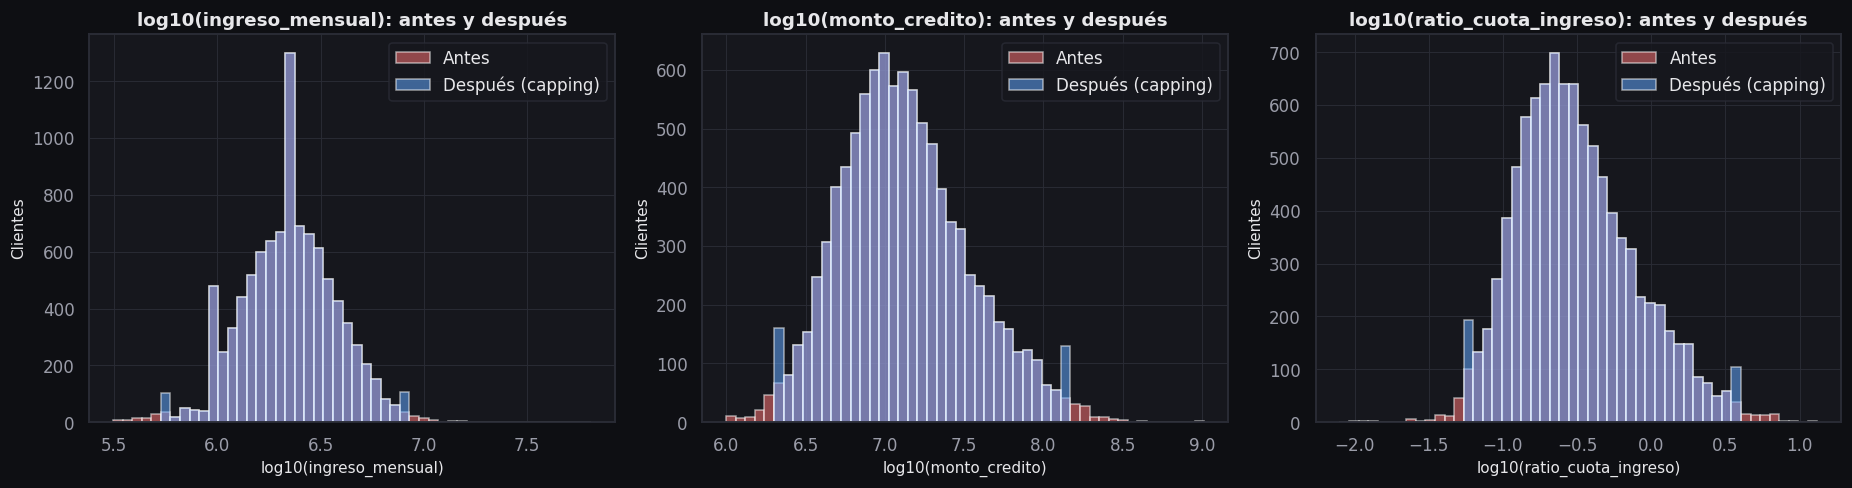

,pearson_antes,pearson_despues,spearman
ingreso_mensual,-0.0590,-0.0710,-0.0840
monto_credito,0.0340,0.0380,-0.0060
cuota_estimada,0.0270,0.0330,-0.0040
ratio_cuota_ingreso,0.0440,0.0560,0.0490
ratio_monto_ingreso,0.0600,0.0690,0.0620
antiguedad_laboral_anios,-0.1120,-0.1120,-0.1080
relacion_deuda_ingreso,0.2990,0.2990,0.3410


In [36]:
VARS_LOG = ["ingreso_mensual", "monto_credito", "ratio_cuota_ingreso"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, c in zip(axes, VARS_LOG):
    bordes = np.histogram_bin_edges(np.log10(df[c]), bins=50)
    series_h = []
    for datos, nombre, color in [(df, "Antes", PALETA["alto"]), (df_cap, "Después (capping)", PALETA["pago"])]:
        conteos = np.histogram(np.log10(datos[c]), bins=bordes)[0]
        ax.hist(np.log10(datos[c]), bins=bordes, alpha=0.55, color=color, label=nombre)
        series_h.append({"nombre": nombre, "conteos": conteos.tolist()})
    ax.set(title=f"log10({c}): antes y después", xlabel=f"log10({c})", ylabel="Clientes")
    ax.legend()
    figura_front("histograma", f"Distribución de log10({c}) antes y después del capping",
                 {"bordes": r4(bordes), "series": series_h}, ejes={"x": f"log10({c})", "y": "Clientes"},
                 clave=f"capping_distribucion_{c}")
plt.show()
pd.DataFrame({"pearson_antes": df[cap].corrwith(df[T]), "pearson_despues": df_cap[cap].corrwith(df_cap[T]),
              "spearman": df[cap].corrwith(df[T], method="spearman")}).round(3)

**Interpretación.** En escala logarítmica, el cuerpo de cada distribución queda intacto; los extremos se
acumulan en una barra en cada límite (en el ingreso, 103 clientes en el límite inferior y 105 en el superior). La
correlación de Pearson con `default` se fortalece al quitar el ruido de los extremos: ingreso de −0,059 a −0,071
(más cerca del −0,084 de Spearman), cuota/ingreso de 0,044 a 0,056 y monto/ingreso de 0,060 a 0,069. Sin perder
ninguna fila, la relación real queda menos oculta.

## 6. IA2.4 · Normalización, estandarización y PCA (sobre datos con atípicos tratados)

In [37]:
NUM_M = columnas_modelo()["numericas"]
X_std = pd.DataFrame(StandardScaler().fit_transform(df_cap[NUM_M]), columns=NUM_M)
X_mm = pd.DataFrame(MinMaxScaler().fit_transform(df_cap[NUM_M]), columns=NUM_M)
pd.concat({"Estandarizado (media, desv.)": X_std.agg(["mean", "std"]).T,
           "Normalizado (mín., máx.)": X_mm.agg(["min", "max"]).T,
           "Normalizado (mediana)": X_mm.median().to_frame("mediana")}, axis=1).round(3)

Estandarizado (media, desv.)        Normalizado (mín., máx.)        Normalizado (mediana)
                                                 mean    std                      min    max               mediana
edad                                          -0.0000 1.0000                   0.0000 1.0000                0.5000
antiguedad_laboral_anios                      -0.0000 1.0000                   0.0000 1.0000                0.1720
personas_a_cargo                               0.0000 1.0000                   0.0000 1.0000                0.1670
ingreso_mensual                               -0.0000 1.0000                   0.0000 1.0000                0.2290
monto_credito                                 -0.0000 1.0000                   0.0000 1.0000                0.0720
plazo_meses                                   -0.0000 1.0000                   0.0000 1.0000                0.2310
tasa_interes_anual                            -0.0000 1.0000                   0.0000 1.0000                0.5060
num_creditos_activos                          -0.0000 1.0000                   0.0000 1.0000                0.1250
moras_ultimos_12m                              0.0000 1.0000                   0.0000 1.0000                0.0000
relacion_deuda_ingreso                         0.0000 1.0000                   0.0000 1.0000                0.3700
puntaje_buro                                   0.0000 1.0000                   0.0000 1.0000                0.7060
uso_cupo_tarjetas                             -0.0000 1.0000                   0.0000 1.0000                0.4530
cuota_estimada                                -0.0000 1.0000                   0.0000 1.0000                0.0520
ratio_cuota_ingreso                            0.0000 1.0000                   0.0000 1.0000                0.0630
ratio_monto_ingreso                           -0.0000 1.0000                   0.0000 1.0000                0.0960
tiene_moras_previas                           -0.0000 1.0000                   0.0000 1.0000                0.0000

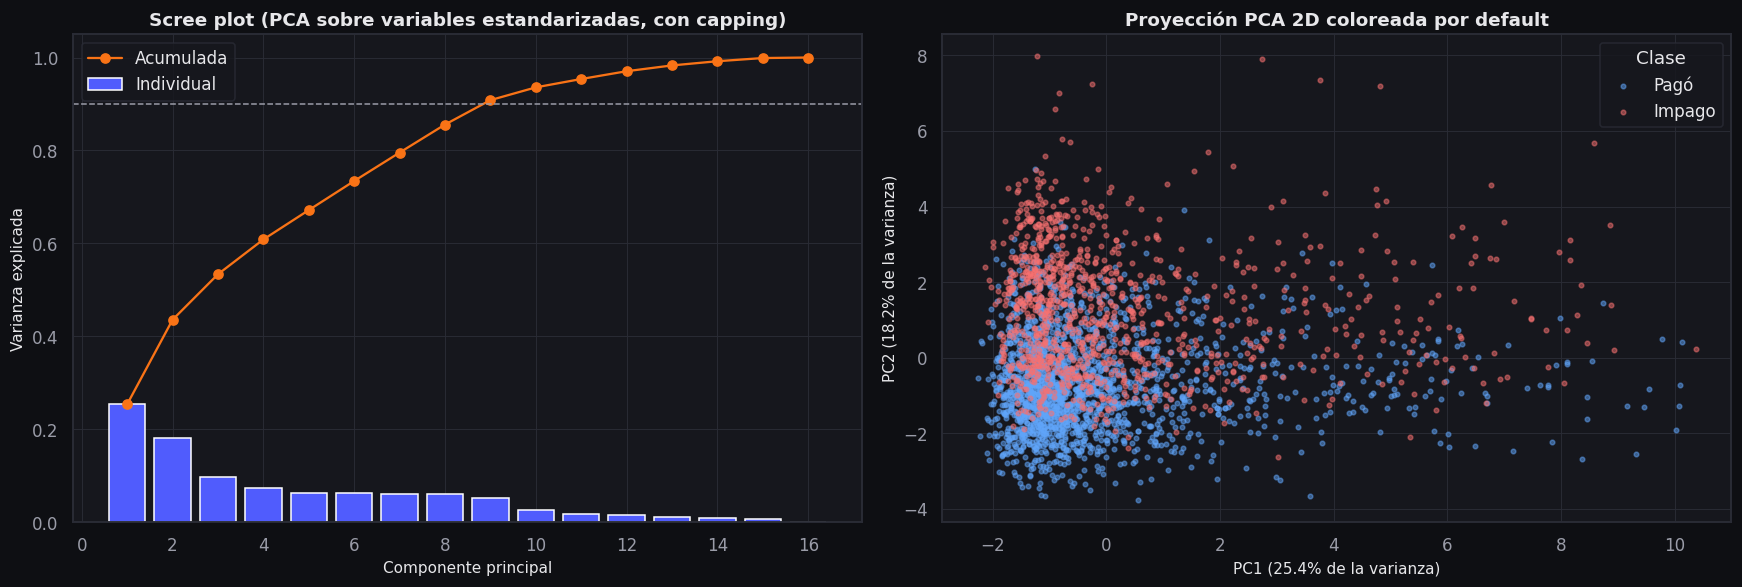

PC1 + PC2 explican 43.6%; se necesitan 9 de 16 componentes para el 90 %


,varianza,media_pago,media_impago,AUC_como_puntaje
PC1,0.2540,-0.1170,0.2120,0.5500
PC2,0.1820,-0.6990,1.2660,0.8270
PC3,0.0980,-0.0650,0.1180,0.5430
PC4,0.0750,-0.0070,0.0120,0.5030


In [38]:
pca = PCA(random_state=config.RANDOM_STATE).fit(X_std)
var = pca.explained_variance_ratio_
acum = np.cumsum(var)
n90 = int(np.argmax(acum >= 0.9) + 1)
Z = pca.transform(X_std)
y_cap = df_cap[T].to_numpy()
idx = np.random.RandomState(config.RANDOM_STATE).choice(len(Z), min(3000, len(Z)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
comp = np.arange(1, len(var) + 1)
axes[0].bar(comp, var, color=PALETA["acento"], label="Individual")
axes[0].plot(comp, acum, marker="o", color=PALETA["programacion"], label="Acumulada")
axes[0].axhline(0.9, ls="--", color=PALETA["texto_suave"], lw=1)
axes[0].set(title="Scree plot (PCA sobre variables estandarizadas, con capping)", xlabel="Componente principal",
            ylabel="Varianza explicada")
axes[0].legend()
for k in (0, 1):
    sel = idx[y_cap[idx] == k]
    axes[1].scatter(Z[sel, 0], Z[sel, 1], s=9, alpha=0.5, color=COLORES_CLASE[k], label=ETIQUETA[k])
axes[1].set(title="Proyección PCA 2D coloreada por default", xlabel=f"PC1 ({var[0]:.1%} de la varianza)",
            ylabel=f"PC2 ({var[1]:.1%} de la varianza)")
axes[1].legend(title="Clase")
plt.show()
figura_front("lineas", "Scree plot del PCA",
             {"series": [{"nombre": "Individual", "x": comp.tolist(), "y": r4(var)},
                         {"nombre": "Acumulada", "x": comp.tolist(), "y": r4(acum)}],
              "referencias": [{"eje": "y", "valor": 0.9, "etiqueta": "90 %"}]},
             ejes={"x": "Componente principal", "y": "Varianza explicada"}, clave="pca_scree", opciones={"formato_y": "pct"})
figura_front("dispersion", "Proyección PCA 2D coloreada por default",
             {"series": [{"nombre": ETIQUETA[k], "puntos": [r4(p) for p in Z[idx[y_cap[idx] == k], :2]]} for k in (0, 1)]},
             ejes={"x": f"PC1 ({var[0]:.1%})", "y": f"PC2 ({var[1]:.1%})"}, clave="pca_proyeccion_2d")
separacion = pd.DataFrame({"varianza": var[:4], "media_pago": [Z[y_cap == 0, i].mean() for i in range(4)],
                           "media_impago": [Z[y_cap == 1, i].mean() for i in range(4)],
                           "AUC_como_puntaje": [max(a, 1 - a) for a in (roc_auc_score(y_cap, Z[:, i]) for i in range(4))]},
                          index=["PC1", "PC2", "PC3", "PC4"])
print(f"PC1 + PC2 explican {var[:2].sum():.1%}; se necesitan {n90} de {len(var)} componentes para el 90 %")
separacion.round(3)

**Interpretación.** La tabla previa confirma las dos escalas: estandarizado con media 0 y desviación 1, y
normalizado en [0, 1]. Aun con el capping, en `MinMaxScaler` las medianas de monto (0,072), cuota (0,052) y
cuota/ingreso (0,063) quedan cerca de 0 por las colas largas, por lo que el PCA se hace sobre las variables
estandarizadas. La varianza está repartida: PC1 explica 25,4 %, PC2 18,2 % (43,6 % juntas) y se necesitan **9 de 16
componentes para el 90 %**. En la proyección 2D las clases se separan a lo largo de **PC2** (AUC de 0,827 usándola
como puntaje; media −0,70 en pagadores y 1,27 en impagos) y apenas en PC1 (AUC 0,55), aunque PC1 tiene más
varianza. La dirección de mayor varianza no es la más predictiva: PCA no sirve para seleccionar variables en
este problema y se mantienen las variables originales, más explicables.

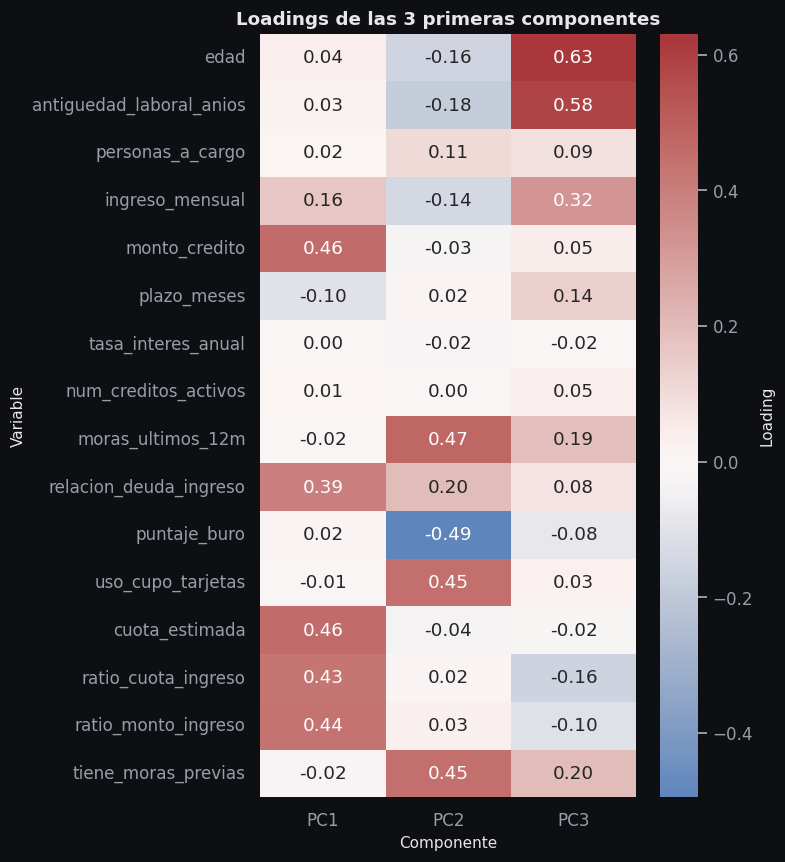

In [39]:
loadings = pd.DataFrame(pca.components_[:3].T, index=NUM_M, columns=["PC1", "PC2", "PC3"])
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={"label": "Loading"})
ax.set(title="Loadings de las 3 primeras componentes", xlabel="Componente", ylabel="Variable")
plt.show()
figura_front("heatmap", "Loadings de las 3 primeras componentes",
             {"x": list(loadings.columns), "y": list(loadings.index), "valores": [r4(f) for f in loadings.to_numpy()]},
             ejes={"x": "Componente", "y": "Variable"}, clave="pca_loadings", opciones={"divergente": True})

**Interpretación.** **PC1** es el eje del **tamaño y la carga del crédito**: monto (0,46), cuota (0,46),
monto/ingreso (0,44), cuota/ingreso (0,43) y deuda/ingreso (0,39). **PC2** es el eje del **comportamiento
crediticio**: buró (−0,49), moras (0,47), uso del cupo (0,45) y tiene moras previas (0,45); por eso separa a los
impagos. **PC3** recoge la **madurez** del cliente: edad (0,63), antigüedad laboral (0,58) e ingreso (0,32).

## 7. IA1.E2 / IA2.E2 · Variables relevantes y decisión de qué entra al modelo

Ranking final sobre train con atípicos tratados: |Pearson| y |Spearman| (numéricas), V de Cramér
(categóricas y binarias) e información mutua (todas). La posición final promedia el rango de asociación
(Spearman o V de Cramér según el tipo) y el de información mutua.

In [40]:
cols_m = columnas_modelo()
X_mi = df_cap[NUM + ["tiene_moras_previas"]].copy()
for c in CAT:
    if c != "tiene_moras_previas":
        X_mi[c] = df_cap[c].astype("category").cat.codes
discretas = [c in CAT for c in X_mi.columns]
mi = pd.Series(mutual_info_classif(X_mi, y_cap, discrete_features=discretas, random_state=config.RANDOM_STATE),
               index=X_mi.columns)
ranking = pd.DataFrame({
    "tipo": ["binaria" if c == "tiene_moras_previas" else "categórica" if c in CAT else "numérica" for c in X_mi.columns],
    "abs_pearson": [abs(df_cap[c].corr(df_cap[T])) if c not in CAT or c == "tiene_moras_previas" else np.nan for c in X_mi.columns],
    "abs_spearman": [abs(df_cap[c].corr(df_cap[T], method="spearman")) if c not in CAT or c == "tiene_moras_previas" else np.nan
                     for c in X_mi.columns],
    "v_cramer": [cramer["v_cramer"].get(c, np.nan) for c in X_mi.columns],
    "info_mutua": mi.values}, index=pd.Index(X_mi.columns, name="variable"))
ranking["asociacion"] = ranking["abs_spearman"].where(ranking["tipo"] == "numérica", ranking["v_cramer"])
ranking["rank"] = (ranking["asociacion"].rank(ascending=False) + ranking["info_mutua"].rank(ascending=False)) / 2
ranking = ranking.sort_values("rank")
EN_MODELO = set(cols_m["numericas"] + cols_m["nominales"] + cols_m["ordinales"])
SENAL_DEBIL = set(leer_json(config.PROCESSED_DIR / "feature_list.json")["seleccion"]["senal_debil"])  # paso 3


def decision(variable: str) -> str:
    if variable == config.SENSITIVE_COL:
        return "Excluida (sensible: solo auditoría)"
    if variable == "longitud_texto":
        return "Fuera del tabular (texto → paso 7)"
    if variable in SENAL_DEBIL:
        return "Entra al modelo (señal débil)"
    return "Entra al modelo" if variable in EN_MODELO else "No entra"


ranking["decision"] = [decision(v) for v in ranking.index]
ranking.round(4).to_csv(config.PROCESSED_DIR / "ranking_variables.csv")
print(f"✔ {ruta(config.PROCESSED_DIR / 'ranking_variables.csv')} · {len(ranking)} variables · "
      f"{ranking['decision'].str.startswith('Entra').sum()} entran al modelo")
ranking.round(4)

✔ db/processed/ranking_variables.csv · 24 variables · 22 entran al modelo


,tipo,abs_pearson,abs_spearman,v_cramer,info_mutua,asociacion,rank,decision
variable,,,,,,,,
puntaje_buro,numérica,0.5344,0.5335,NaN,0.1654,0.5335,1.0000,Entra al modelo
uso_cupo_tarjetas,numérica,0.4995,0.4988,NaN,0.1355,0.4988,2.0000,Entra al modelo
moras_ultimos_12m,numérica,0.3883,0.3873,NaN,0.0802,0.3873,3.0000,Entra al modelo
tiene_moras_previas,binaria,0.3588,0.3588,0.3586,0.0635,0.3586,4.5000,Entra al modelo
relacion_deuda_ingreso,numérica,0.2987,0.3415,NaN,0.0682,0.3415,4.5000,Entra al modelo
situacion_laboral,categórica,NaN,NaN,0.1709,0.0144,0.1709,6.0000,Entra al modelo
antiguedad_laboral_anios,numérica,0.1121,0.1080,NaN,0.0082,0.1080,8.0000,Entra al modelo
nivel_educativo,categórica,NaN,NaN,0.1082,0.0061,0.1082,8.5000,Entra al modelo
personas_a_cargo,numérica,0.0774,0.0747,NaN,0.0061,0.0747,10.0000,Entra al modelo


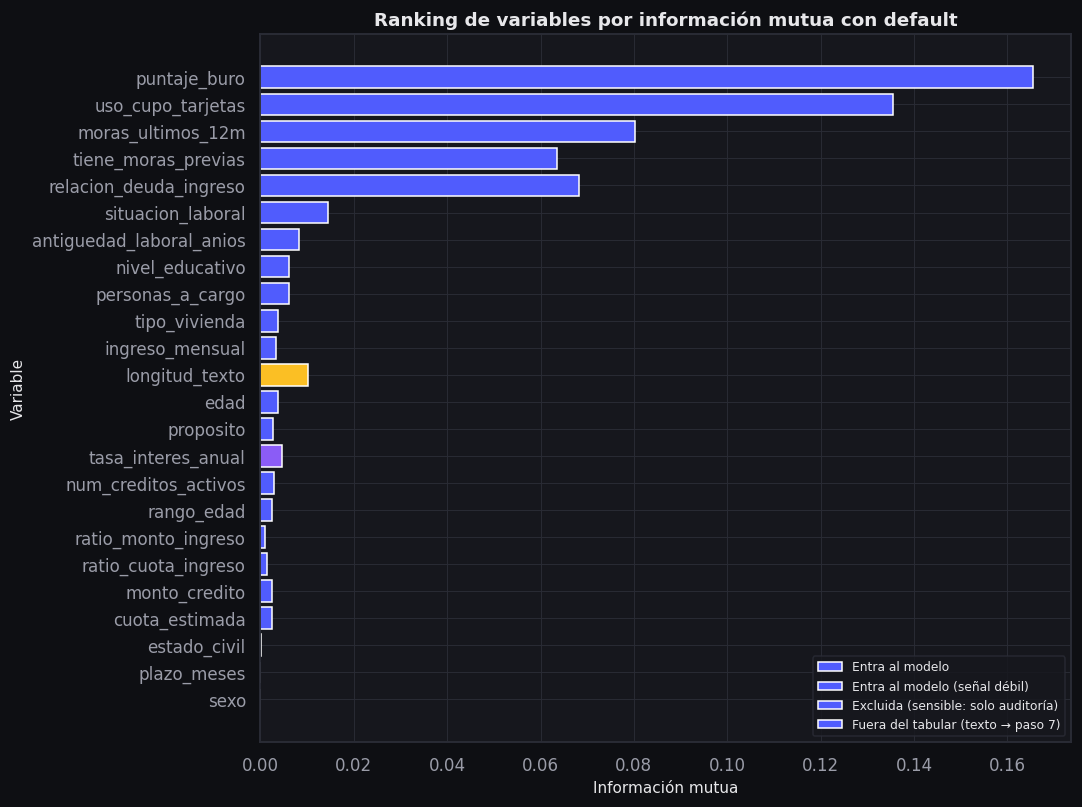

In [41]:
fig, ax = plt.subplots(figsize=(10, 7.5))
r = ranking.iloc[::-1]
color_dec = {"Entra al modelo": PALETA["acento"], "Entra al modelo (señal débil)": PALETA["ia"],
             "Excluida (sensible: solo auditoría)": PALETA["alto"],
             "Fuera del tabular (texto → paso 7)": PALETA["medio"], "No entra": PALETA["texto_suave"]}
ax.barh(r.index, r["info_mutua"], color=[color_dec[d] for d in r["decision"]])
for d, color in color_dec.items():
    if d in set(r["decision"]):
        ax.barh([], [], color=color, label=d)
ax.legend(loc="lower right", fontsize=8)
ax.set(title="Ranking de variables por información mutua con default", xlabel="Información mutua", ylabel="Variable")
plt.show()
figura_front("barras_h", "Ranking de variables por información mutua con default",
             {"categorias": list(ranking.index), "series": [{"nombre": "Información mutua", "valores": r4(ranking["info_mutua"])}],
              "grupos": list(ranking["decision"])},
             ejes={"x": "Información mutua", "y": "Variable"}, clave="ranking_variables", opciones={"color_por": "decision"})

**Interpretación y decisión.** El ranking ubica arriba a `puntaje_buro`, `uso_cupo_tarjetas`, `moras_ultimos_12m`,
`tiene_moras_previas` y `relacion_deuda_ingreso`, seguidas de `situacion_laboral`, `antiguedad_laboral_anios` y
`nivel_educativo`, igual que la selección del paso 3. **Decisión:** entran al modelo las 22 variables de
`columnas_modelo()` (16 numéricas, 4 nominales y 2 ordinales), sin cambios respecto al paso 3 y sin cambios en
`features.py`, que ya incluye el capping p1-p99. `estado_civil` y `plazo_meses` quedan al final (V = 0 e
información mutua ≈ 0) y, con `tasa_interes_anual`, son las tres de señal débil del paso 3. Aquí la tasa queda
en el puesto 15,5 solo porque el estimador de información mutua por vecinos le asigna 0,0046, pese a una
correlación de 0,005; en el paso 3 su información mutua fue 0. Las tres siguen en el modelo y se revisan con la
importancia por permutación del paso 5. `sexo` queda excluida y su exclusión no cuesta información (V = 0,
información mutua 0). `longitud_texto` tiene señal (información mutua 0,010, puesto 11,5), pero queda **fuera del
modelo tabular**: el texto se evalúa aparte en el paso 7 (ΔAUC), coherente con `config.NUM_MODELO`.

In [42]:
top = ranking.head(5).index.tolist()
display(Markdown(
    f"**Resumen calculado.** Train con {len(df):,} clientes y tasa de impago de {TASA:.2%}. Las cinco variables "
    f"mejor posicionadas son {', '.join(f'`{v}`' for v in top)}. Correlación de Spearman con el impago: buró "
    f"{corr_obj.loc['puntaje_buro', 'spearman']:.3f}, uso del cupo {corr_obj.loc['uso_cupo_tarjetas', 'spearman']:.3f}, "
    f"moras {corr_obj.loc['moras_ultimos_12m', 'spearman']:.3f}. V de Cramér: moras previas "
    f"{cramer.loc['tiene_moras_previas', 'v_cramer']:.3f}, situación laboral {cramer.loc['situacion_laboral', 'v_cramer']:.3f}, "
    f"sexo {cramer.loc['sexo', 'v_cramer']:.3f}. El capping p1-p99 recortó a lo sumo "
    f"{int(tratamiento['filas_recortadas_train'].max())} filas por variable en train sin eliminar ninguna (la asimetría "
    f"del ingreso pasó de {tratamiento.loc['ingreso_mensual', 'asimetria_antes']:.2f} a "
    f"{tratamiento.loc['ingreso_mensual', 'asimetria_despues']:.2f}). El PCA necesita {n90} de {len(var)} componentes "
    f"para el 90 % de la varianza; PC1 + PC2 explican {var[:2].sum():.1%}. "
    f"{ranking['decision'].str.startswith('Entra').sum()} de {len(ranking)} variables entran al modelo tabular "
    f"({(ranking['decision'] == 'Entra al modelo (señal débil)').sum()} con señal débil)."))

**Resumen calculado.** Train con 9,600 clientes y tasa de impago de 35.56%. Las cinco variables mejor posicionadas son `puntaje_buro`, `uso_cupo_tarjetas`, `moras_ultimos_12m`, `tiene_moras_previas`, `relacion_deuda_ingreso`. Correlación de Spearman con el impago: buró -0.533, uso del cupo 0.499, moras 0.387. V de Cramér: moras previas 0.359, situación laboral 0.171, sexo 0.000. El capping p1-p99 recortó a lo sumo 192 filas por variable en train sin eliminar ninguna (la asimetría del ingreso pasó de 10.81 a 1.44). El PCA necesita 9 de 16 componentes para el 90 % de la varianza; PC1 + PC2 explican 43.6%. 22 de 24 variables entran al modelo tabular (3 con señal débil).

## Conclusiones

- **IA1.2 / IA1.E1 · EDA.** Las variables monetarias son muy asimétricas (asimetría del ingreso 10,8). En el
  bivariado, 12 de 16 numéricas difieren entre clases, pero monto, plazo, tasa y cuota no. En el multivariado,
  los factores se acumulan: un desempleado con moras y buró < 600 llega a 90,3 % de impago y un empleado sin moras
  con buró > 800 se queda en 4,8 %. DuckDB mostró que el buró < 600 es el 17 % de la cartera y el 39 % de los
  impagos.
- **IA2.1 / IA2.2 · Manipulación.** Se aplicaron `merge`, `melt`/`pivot`, `map`/`apply`, `cut`/`qcut`, `groupby`
  con varias agregaciones, `assign` y `pipe`, y cada verbo de dplyr (`filter`, `select`, `mutate`,
  `group_by` + `summarise`, `arrange`, `%>%`) se ejecutó con su equivalente encadenado en pandas, con el código R
  solo como referencia.
- **IA2.3 · Visualización.** Matplotlib (panel de 2×2), Seaborn (heatmap, pairplot y violinplot) y tres gráficos
  de plotnine con `geom_boxplot`, `geom_col` y `geom_line` + `geom_point`, todos con `facet_wrap`.
- **IA2.E1 · Patrones.** Las asociaciones más fuertes son las del buró (−0,53), el uso del cupo (0,50), las
  moras (0,39; V = 0,36) y la deuda/ingreso (0,34). Pearson se distorsiona con los atípicos de las monetarias.
  Se formularon cinco hipótesis: domina el historial, el endeudamiento anticipa, la estabilidad protege, las
  condiciones del crédito no discriminan solas y, entre las sensibles, solo la edad tiene efecto.
- **IA2.5 · Atípicos.** Detectados con IQR y z-score y tratados con `Winsorizer` (p1-p99 ajustado en train,
  los mismos límites del paso 3). Se recortó el 2 % de las filas por variable y **no se eliminó ninguna**:
  eliminar habría costado el 23,8 % de train. La asimetría del ingreso cae de 10,81 a 1,44.
- **IA2.4 · Escalas y PCA.** Se compararon estandarización y normalización. En el PCA, 9 de 16 componentes
  explican el 90 %; PC2 (comportamiento crediticio) separa las clases (AUC 0,83) y PC1 (tamaño del crédito) no.
- **IA1.E2 / IA2.E2 · Variables.** El ranking (correlación, información mutua y V de Cramér) está en
  `db/processed/ranking_variables.csv`. Entran al modelo las 22 variables de `columnas_modelo()`, tres de ellas con
  señal débil; `sexo` queda excluida y `longitud_texto` queda fuera del tabular (paso 7). No se requieren cambios en
  `features.py`.